#Part 1: Project Introduction, Import Libraries, Load Dataset, Data Overview & Data Cleaning
# Loan Default Prediction using Machine Learning

## Credit Risk Modelling Project

### Problem Statement

Financial institutions issue thousands of home equity loans every year. While these loans generate significant interest income, they also expose banks to credit risk when borrowers fail to repay their obligations.

The objective of this project is to develop an interpretable machine learning model capable of predicting whether a customer is likely to default on a home equity loan.

The model will help the bank:

- Identify high-risk applicants before loan approval.
- Reduce financial losses caused by loan defaults.
- Improve the efficiency of the loan approval process.
- Support data-driven credit risk assessment.
- Provide explainable predictions using Explainable AI (SHAP).

---

## Business Objective

The primary objective is **not simply maximizing accuracy**, but minimizing the number of defaulters incorrectly classified as non-defaulters.

Therefore, Recall will be the primary evaluation metric, followed by Precision, F1-Score and ROC-AUC.

---

## Dataset

The Home Equity (HMEQ) dataset contains information on **5,960 home equity loans**.

Target Variable:

**BAD**

- 1 → Default
- 0 → Non-default

There are **12 predictor variables** describing applicant characteristics, loan information, property value, employment history and credit history.

---

## Project Workflow

1. Data Understanding
2. Data Cleaning
3. Exploratory Data Analysis
4. Missing Value Treatment
5. Outlier Treatment
6. Feature Engineering
7. Model Building
8. Hyperparameter Tuning
9. Model Explainability
10. Business Recommendations

In [2]:
# ============================================================
# Import Required Libraries
# ============================================================

# Data Manipulation
import numpy as np
import pandas as pd

# Data Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Machine Learning

from sklearn.model_selection import (
    train_test_split,
    GridSearchCV,
    RandomizedSearchCV
)

from sklearn.preprocessing import (
    StandardScaler,
    LabelEncoder
)

from sklearn.compose import ColumnTransformer

from sklearn.pipeline import Pipeline

from sklearn.impute import SimpleImputer

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)

# Models

from sklearn.linear_model import LogisticRegression

from sklearn.ensemble import RandomForestClassifier

from xgboost import XGBClassifier

# Explainability

import shap

# Statistical Analysis

from scipy.stats import zscore

# Ignore warnings

import warnings
warnings.filterwarnings("ignore")

# Display Settings

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

# Plot Style

plt.style.use("ggplot")
sns.set(font_scale=1.1)

print("Libraries Imported Successfully.")

Libraries Imported Successfully.


In [4]:
# Load Dataset
# ============================================================
# Load Dataset
# ============================================================

df = pd.read_csv(
    r"C:\Users\sagni\Downloads\Loan Default Prediction Data\hmeq.csv"
)

# Create a copy of original dataset

loan_df = df.copy()

print("Dataset Loaded Successfully.")

Dataset Loaded Successfully.


In [6]:
# View first five observations

loan_df.head()

,BAD,LOAN,MORTDUE,VALUE,REASON,JOB,YOJ,DEROG,DELINQ,CLAGE,NINQ,CLNO,DEBTINC
0,1,1100,25860.0,39025.0,HomeImp,Other,10.5,0.0,0.0,94.366667,1.0,9.0,NaN
1,1,1300,70053.0,68400.0,HomeImp,Other,7.0,0.0,2.0,121.833333,0.0,14.0,NaN
2,1,1500,13500.0,16700.0,HomeImp,Other,4.0,0.0,0.0,149.466667,1.0,10.0,NaN
3,1,1500,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,0,1700,97800.0,112000.0,HomeImp,Office,3.0,0.0,0.0,93.333333,0.0,14.0,NaN


# Data Overview

Before building any machine learning model, it is essential to understand the structure and quality of the dataset.

This section explores:

- Dataset dimensions
- Variable names
- Data types
- Missing values
- Duplicate records
- Summary statistics

In [9]:
# Shape of dataset

loan_df.shape
# Number of Rows and Columns

print(f"Number of Rows    : {loan_df.shape[0]}")
print(f"Number of Columns : {loan_df.shape[1]}")


Number of Rows    : 5960
Number of Columns : 13


In [11]:
# Display column names

loan_df.columns


Index(['BAD', 'LOAN', 'MORTDUE', 'VALUE', 'REASON', 'JOB', 'YOJ', 'DEROG',
       'DELINQ', 'CLAGE', 'NINQ', 'CLNO', 'DEBTINC'],
      dtype='object')

In [13]:
# Display complete information about dataset

loan_df.info()
# Data Types

loan_df.dtypes
# Summary statistics of numerical variables

loan_df.describe().T
# Summary statistics including categorical variables

loan_df.describe(include='all').T


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5960 entries, 0 to 5959
Data columns (total 13 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   BAD      5960 non-null   int64  
 1   LOAN     5960 non-null   int64  
 2   MORTDUE  5442 non-null   float64
 3   VALUE    5848 non-null   float64
 4   REASON   5708 non-null   object 
 5   JOB      5681 non-null   object 
 6   YOJ      5445 non-null   float64
 7   DEROG    5252 non-null   float64
 8   DELINQ   5380 non-null   float64
 9   CLAGE    5652 non-null   float64
 10  NINQ     5450 non-null   float64
 11  CLNO     5738 non-null   float64
 12  DEBTINC  4693 non-null   float64
dtypes: float64(9), int64(2), object(2)
memory usage: 605.4+ KB


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
BAD,5960.0,NaN,NaN,NaN,0.199497,0.399656,0.0,0.0,0.0,0.0,1.0
LOAN,5960.0,NaN,NaN,NaN,18607.969799,11207.480417,1100.0,11100.0,16300.0,23300.0,89900.0
MORTDUE,5442.0,NaN,NaN,NaN,73760.8172,44457.609458,2063.0,46276.0,65019.0,91488.0,399550.0
VALUE,5848.0,NaN,NaN,NaN,101776.048741,57385.775334,8000.0,66075.5,89235.5,119824.25,855909.0
REASON,5708,2,DebtCon,3928,NaN,NaN,NaN,NaN,NaN,NaN,NaN
JOB,5681,6,Other,2388,NaN,NaN,NaN,NaN,NaN,NaN,NaN
YOJ,5445.0,NaN,NaN,NaN,8.922268,7.573982,0.0,3.0,7.0,13.0,41.0
DEROG,5252.0,NaN,NaN,NaN,0.25457,0.846047,0.0,0.0,0.0,0.0,10.0
DELINQ,5380.0,NaN,NaN,NaN,0.449442,1.127266,0.0,0.0,0.0,0.0,15.0
CLAGE,5652.0,NaN,NaN,NaN,179.766275,85.810092,0.0,115.116702,173.466667,231.562278,1168.233561


In [15]:
# Check missing values

loan_df.isnull().sum()
# Missing values in percentage

missing_percent = (
    loan_df.isnull().sum() /
    len(loan_df)
)*100

missing_percent.sort_values(
    ascending=False
)

DEBTINC    21.258389
DEROG      11.879195
DELINQ      9.731544
MORTDUE     8.691275
YOJ         8.640940
NINQ        8.557047
CLAGE       5.167785
JOB         4.681208
REASON      4.228188
CLNO        3.724832
VALUE       1.879195
BAD         0.000000
LOAN        0.000000
dtype: float64

In [17]:
# Duplicate observations

loan_df.duplicated().sum()
# Check unique values

loan_df.nunique()

BAD           2
LOAN        540
MORTDUE    5053
VALUE      5381
REASON        2
JOB           6
YOJ          99
DEROG        11
DELINQ       14
CLAGE      5314
NINQ         16
CLNO         62
DEBTINC    4693
dtype: int64

# Data Cleaning

The objective of this section is to improve the quality of the dataset before Exploratory Data Analysis.

The following steps are performed:

- Remove duplicate observations
- Convert variables into appropriate data types
- Verify target variable
- Identify numerical and categorical variables

In [20]:
# Remove duplicate records

loan_df = loan_df.drop_duplicates()

print("Dataset Shape After Removing Duplicates:")
print(loan_df.shape)

# Display first few rows again

loan_df.head()
# Convert categorical columns

categorical_cols = ['BAD','REASON','JOB']

for col in categorical_cols:
    loan_df[col] = loan_df[col].astype("category")




Dataset Shape After Removing Duplicates:
(5960, 13)


In [22]:
loan_df.dtypes
# Separate Numerical and Categorical Columns

numerical_columns = loan_df.select_dtypes(
    include=['int64','float64']
).columns.tolist()

categorical_columns = loan_df.select_dtypes(
    include=['category','object']
).columns.tolist()

print("Numerical Variables")
print(numerical_columns)

print("\nCategorical Variables")
print(categorical_columns)

Numerical Variables
['LOAN', 'MORTDUE', 'VALUE', 'YOJ', 'DEROG', 'DELINQ', 'CLAGE', 'NINQ', 'CLNO', 'DEBTINC']

Categorical Variables
['BAD', 'REASON', 'JOB']


In [24]:
# Check target Variable
# Check target variable distribution

loan_df['BAD'].value_counts()
# Target variable percentage

loan_df['BAD'].value_counts(normalize=True)*100
# Final Dataset Information

loan_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5960 entries, 0 to 5959
Data columns (total 13 columns):
 #   Column   Non-Null Count  Dtype   
---  ------   --------------  -----   
 0   BAD      5960 non-null   category
 1   LOAN     5960 non-null   int64   
 2   MORTDUE  5442 non-null   float64 
 3   VALUE    5848 non-null   float64 
 4   REASON   5708 non-null   category
 5   JOB      5681 non-null   category
 6   YOJ      5445 non-null   float64 
 7   DEROG    5252 non-null   float64 
 8   DELINQ   5380 non-null   float64 
 9   CLAGE    5652 non-null   float64 
 10  NINQ     5450 non-null   float64 
 11  CLNO     5738 non-null   float64 
 12  DEBTINC  4693 non-null   float64 
dtypes: category(3), float64(9), int64(1)
memory usage: 483.7 KB


# Initial Observations

After performing the initial data inspection, the following observations were made:

### Dataset Characteristics

- The dataset contains loan applicant information and loan repayment status.
- The target variable (BAD) is binary.
- Both numerical and categorical variables are present.

### Missing Values

Several variables contain missing observations, particularly:

- DEBTINC
- MORTDUE
- VALUE
- YOJ
- DEROG
- DELINQ
- CLAGE
- NINQ
- CLNO

Missing values will be treated in the preprocessing stage.

### Duplicate Records

Duplicate observations were checked and removed (if any).

### Class Distribution

The target variable is moderately imbalanced, with approximately 20% defaulters and 80% non-defaulters.

This indicates that evaluation metrics such as Recall, Precision, F1-score, ROC-AUC and Precision-Recall Curve are more appropriate than Accuracy alone.

# Part 2: Exploratory Data Analysis (EDA)
# Exploratory Data Analysis (EDA)

## Objective

Exploratory Data Analysis (EDA) is performed to better understand the characteristics of the dataset before applying machine learning algorithms.

The objectives of this section are:

- Understand the distribution of numerical variables.
- Analyze categorical variables.
- Study the relationship between independent variables and the target variable.
- Detect skewness and potential outliers.
- Identify important variables associated with loan default.
- Generate business insights that can support loan approval decisions.

EDA is divided into:

1. Univariate Analysis
2. Bivariate Analysis
3. Multivariate Analysis
4. Correlation Analysis

# Univariate Analysis

Univariate analysis focuses on analyzing one variable at a time.

It helps us understand:

- Distribution
- Central tendency
- Spread
- Presence of skewness
- Presence of outliers
- Class imbalance

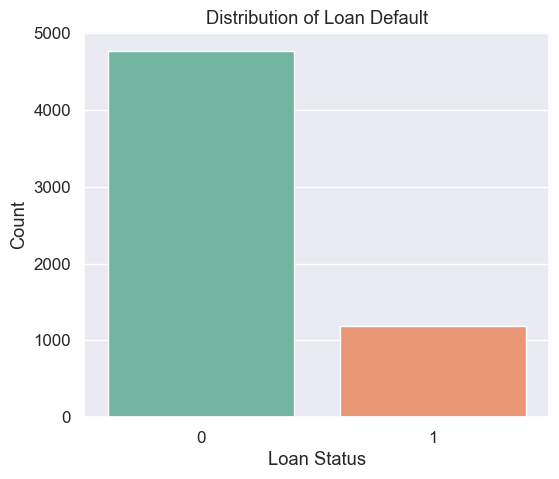

BAD
0    80.050336
1    19.949664
Name: proportion, dtype: float64

In [29]:
#1 Target Variable Distribution
# Target Variable Distribution

plt.figure(figsize=(6,5))

sns.countplot(
    data=loan_df,
    x='BAD',
    palette='Set2'
)

plt.title("Distribution of Loan Default")
plt.xlabel("Loan Status")
plt.ylabel("Count")

plt.show()

# Percentage Distribution

loan_df['BAD'].value_counts(normalize=True)*100

### Insight

- Around 80% of customers repaid their loans.
- Approximately 20% of customers defaulted.
- The dataset is moderately imbalanced.
- Therefore, Recall and F1-score will be more suitable evaluation metrics than Accuracy.

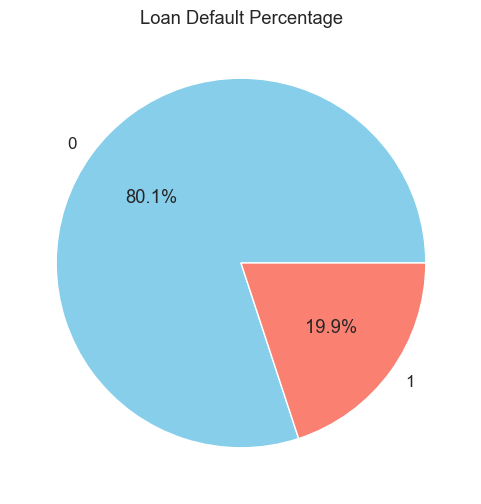

In [32]:
#2 Pie Chart
loan_df['BAD'].value_counts().plot(
    kind='pie',
    autopct='%1.1f%%',
    figsize=(6,6),
    colors=['skyblue','salmon']
)

plt.ylabel("")
plt.title("Loan Default Percentage")
plt.show()

In [34]:
#3 Numerical Variable Distribution
numerical_columns

['LOAN',
 'MORTDUE',
 'VALUE',
 'YOJ',
 'DEROG',
 'DELINQ',
 'CLAGE',
 'NINQ',
 'CLNO',
 'DEBTINC']

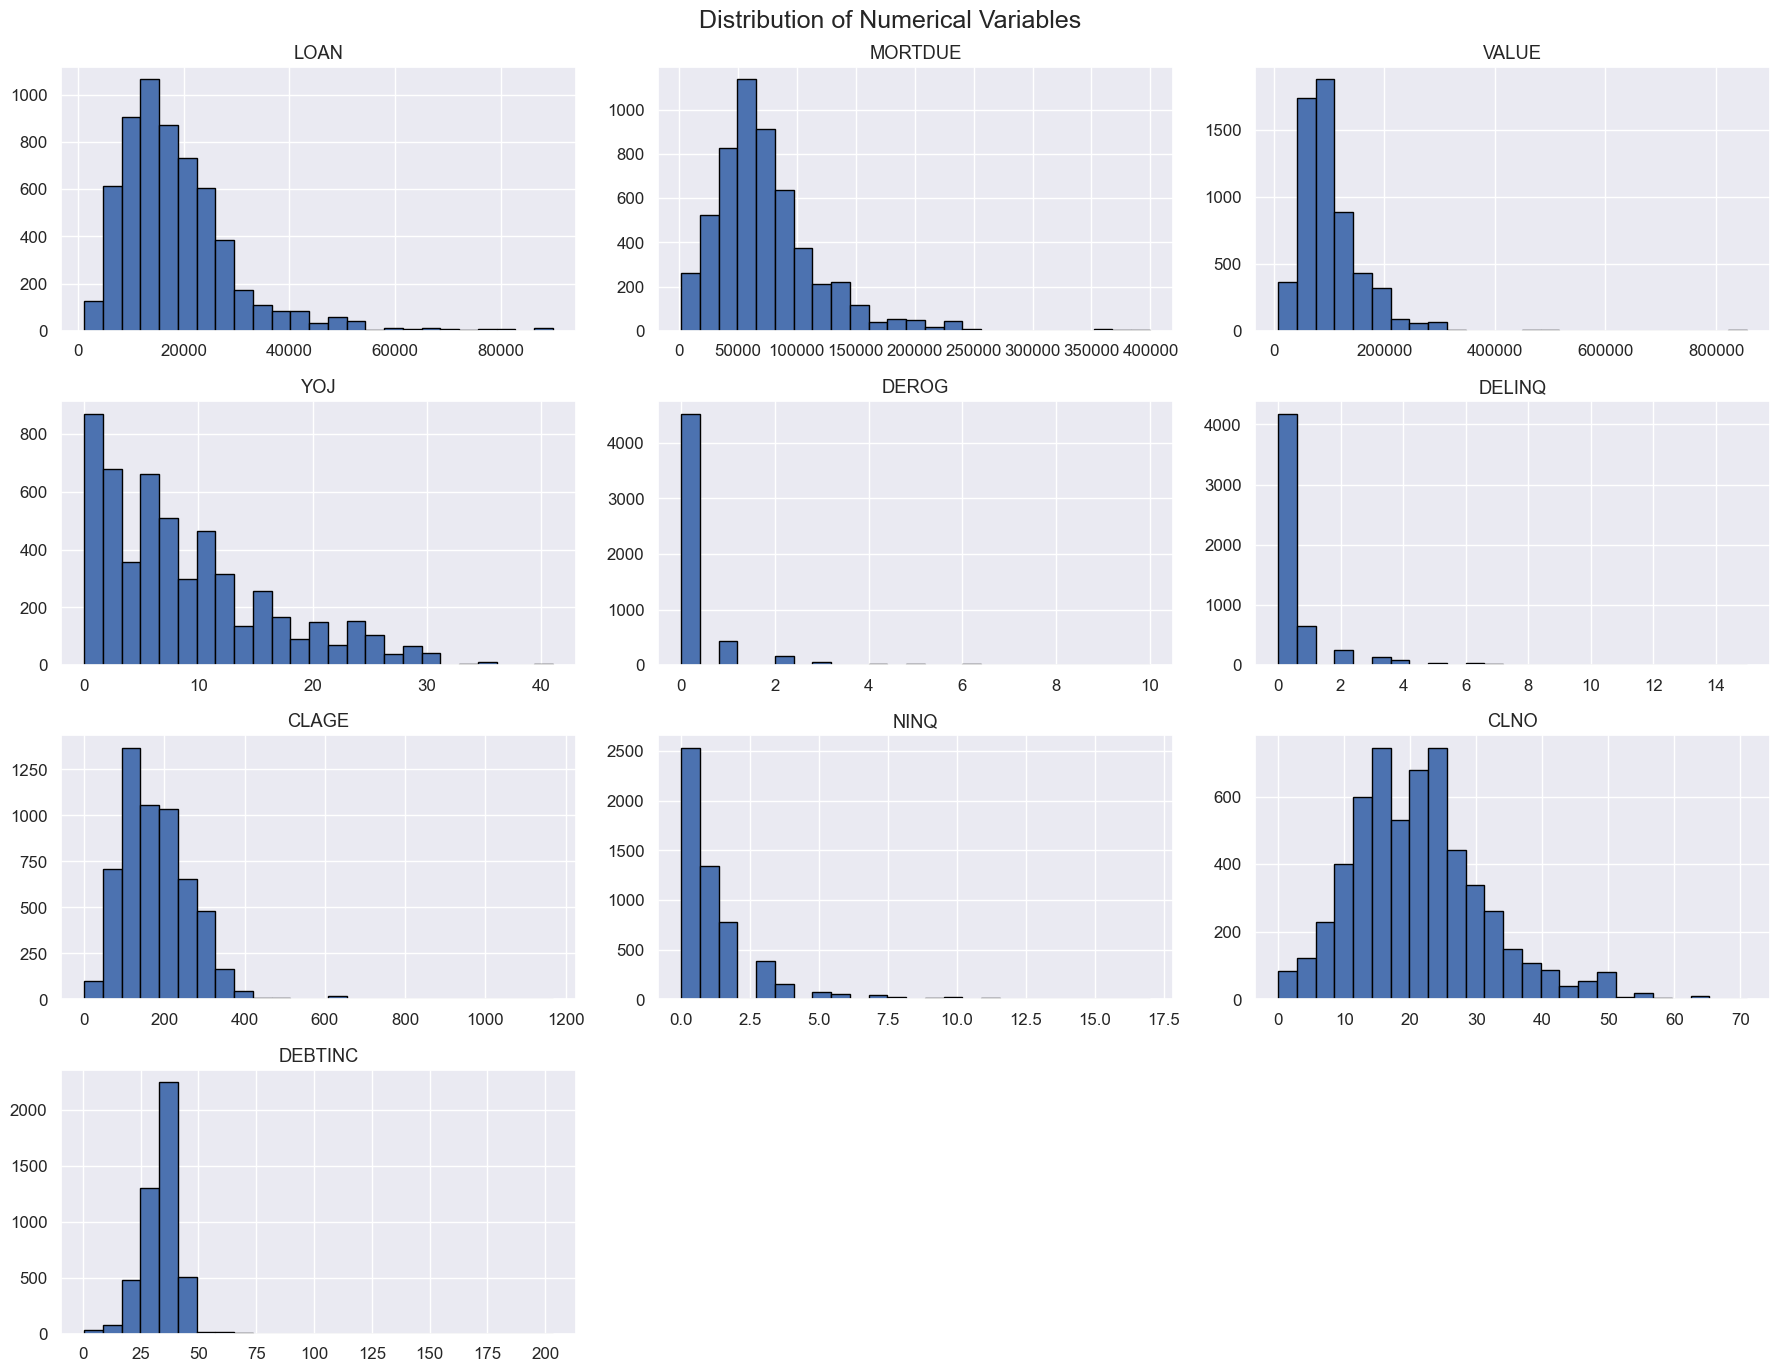

In [36]:
# Histogram

loan_df[numerical_columns].hist(
    figsize=(18,14),
    bins=25,
    edgecolor='black'
)

plt.suptitle("Distribution of Numerical Variables", fontsize=18)

plt.tight_layout()

plt.show()

### Insight

Most numerical variables are positively skewed, indicating the presence of customers with unusually large loan amounts or debt values.

Several variables may require transformation or outlier treatment before model development.

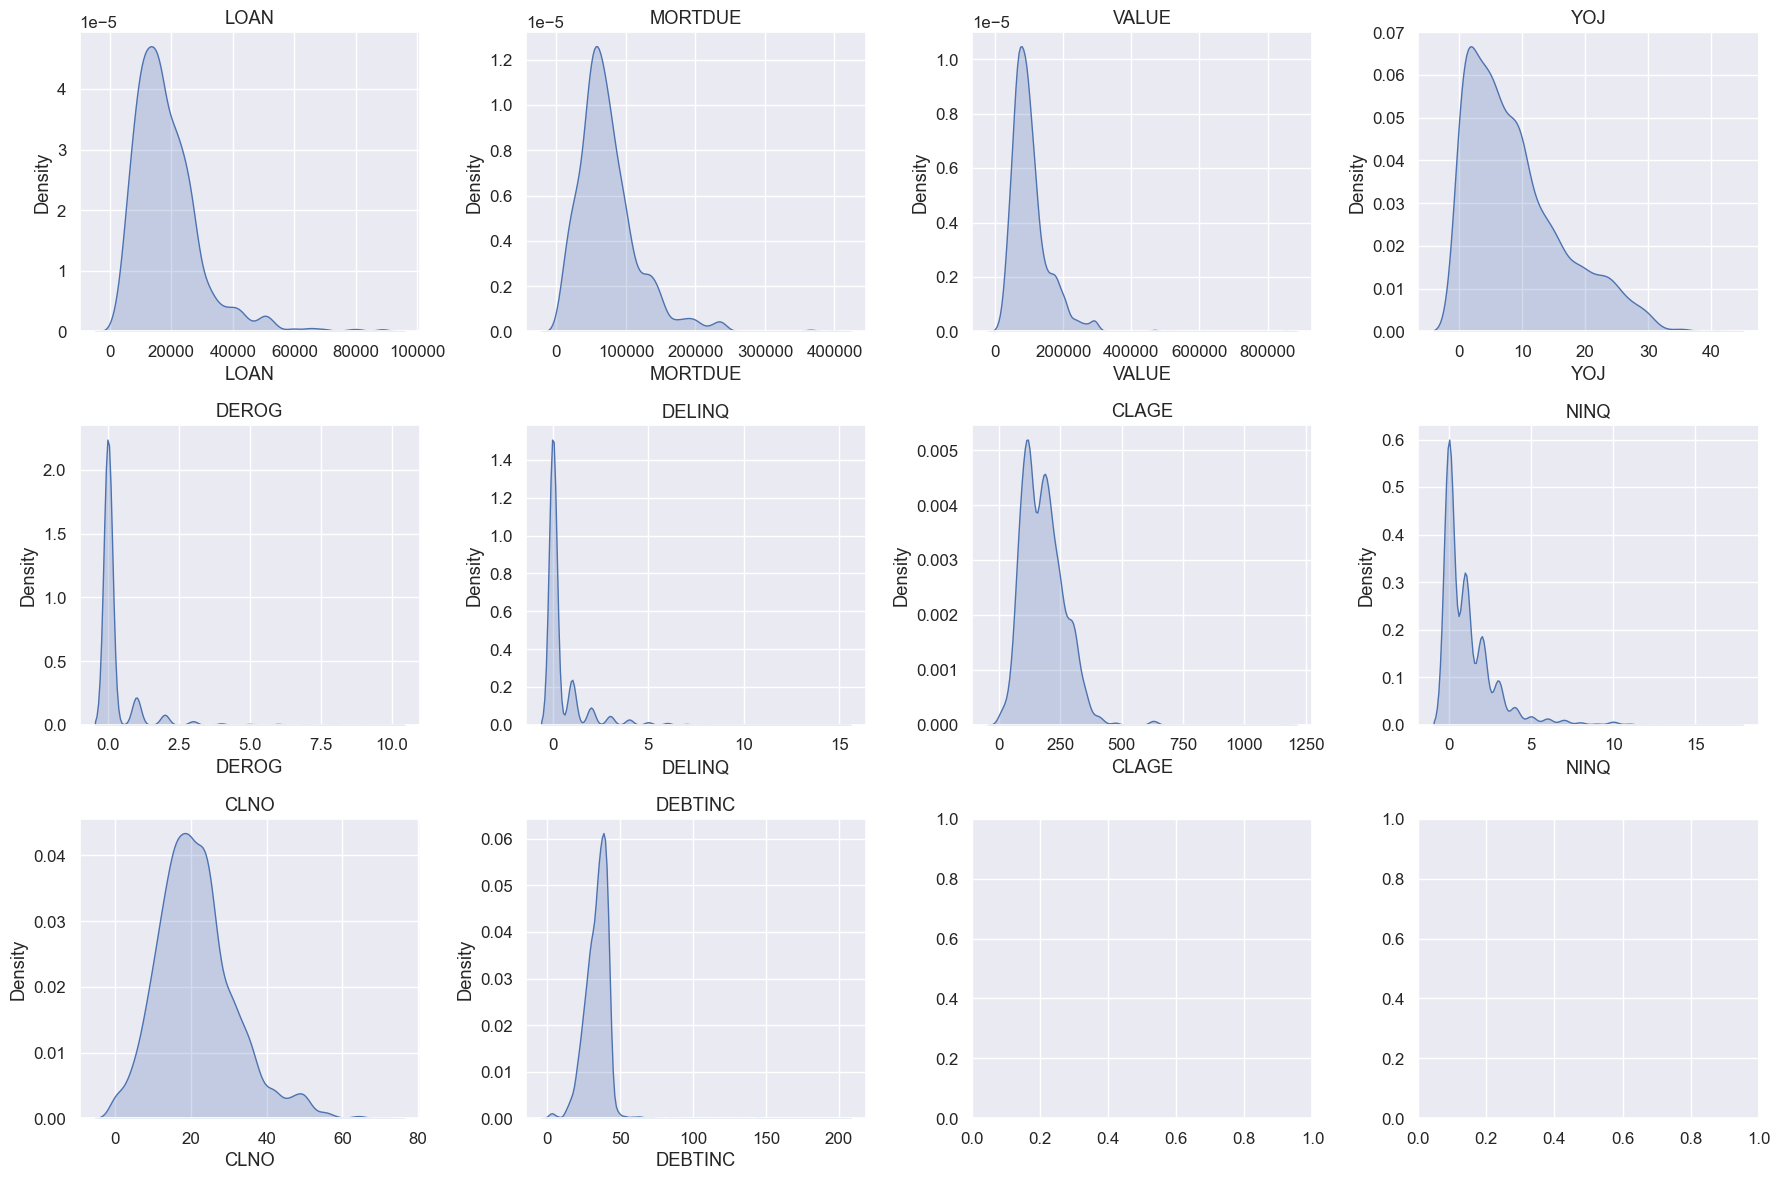

In [39]:
#KDE Plot
fig, axes = plt.subplots(3,4, figsize=(18,12))

axes = axes.flatten()

for i,col in enumerate(numerical_columns):

    sns.kdeplot(
        loan_df[col],
        fill=True,
        ax=axes[i]
    )

    axes[i].set_title(col)

plt.tight_layout()

plt.show()

### Insight

The KDE plots reveal that several variables such as LOAN, MORTDUE, VALUE and DEBTINC exhibit long right tails, indicating high-value borrowers.

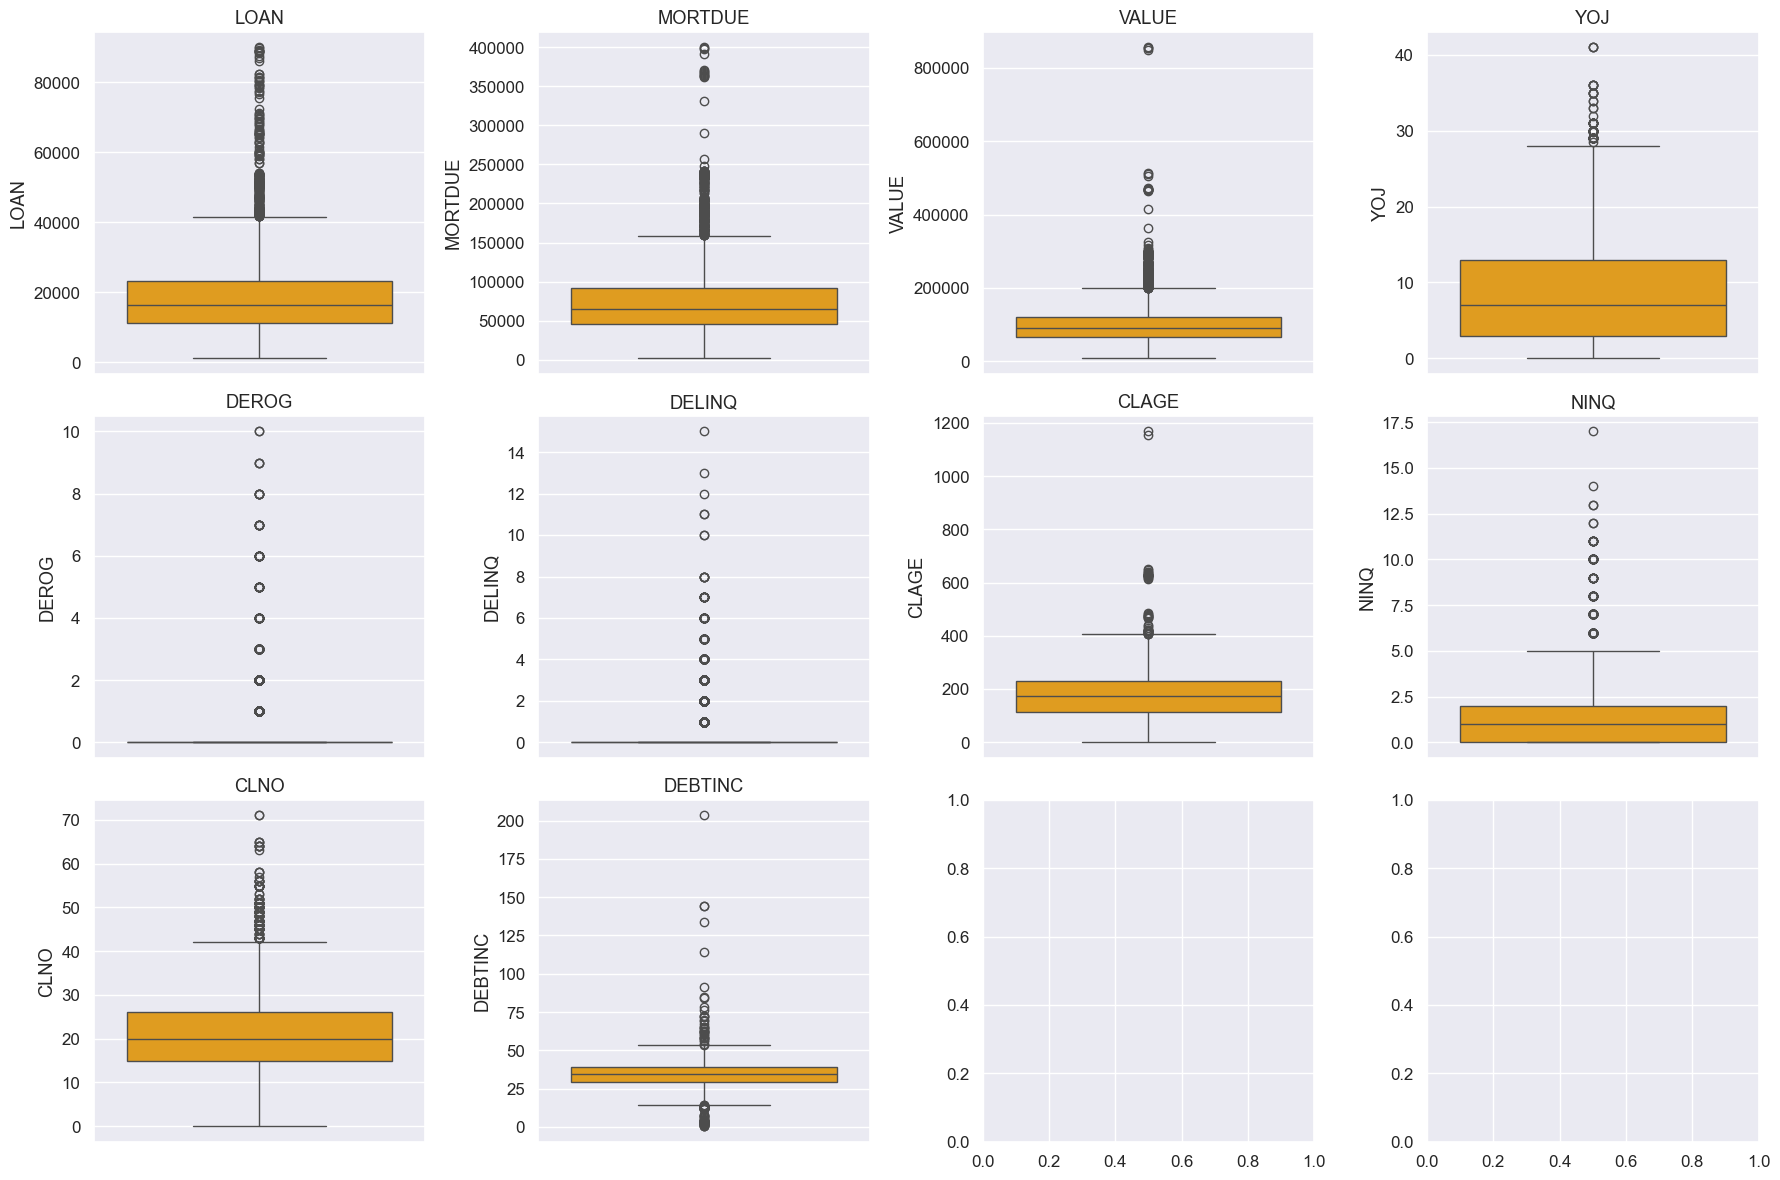

In [42]:
#Boxplots
fig, axes = plt.subplots(3,4, figsize=(18,12))

axes = axes.flatten()

for i,col in enumerate(numerical_columns):

    sns.boxplot(
        y=loan_df[col],
        ax=axes[i],
        color='orange'
    )

    axes[i].set_title(col)

plt.tight_layout()

plt.show()

#### Insight

Most financial variables contain extreme values.

These observations are expected in credit risk datasets and should not be removed without business justification.

In [45]:
#Categorical Variables
categorical_columns

['BAD', 'REASON', 'JOB']

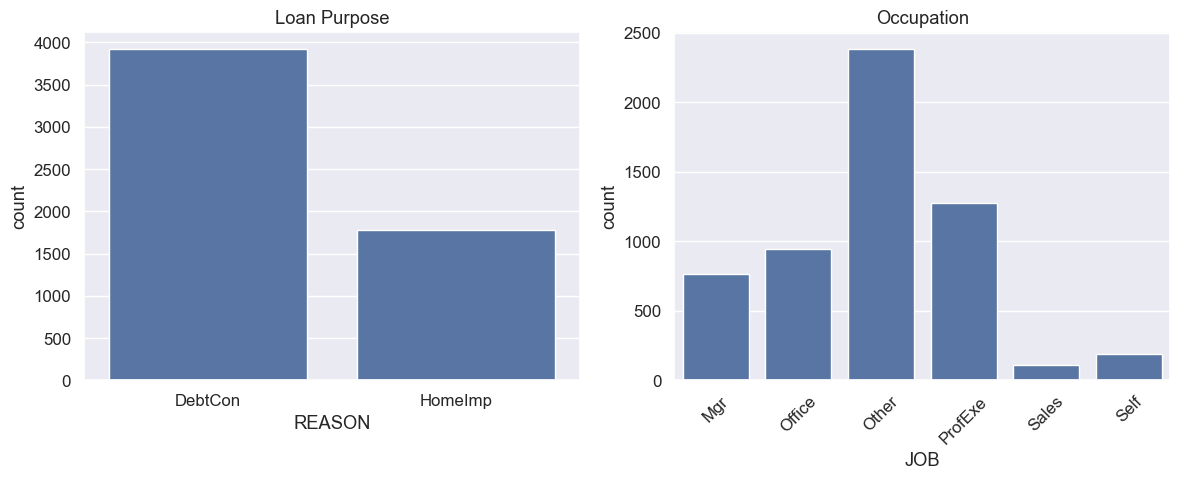

In [47]:
fig, axes = plt.subplots(1,2, figsize=(12,5))

sns.countplot(
    data=loan_df,
    x='REASON',
    ax=axes[0]
)

axes[0].set_title("Loan Purpose")

sns.countplot(
    data=loan_df,
    x='JOB',
    ax=axes[1]
)

axes[1].tick_params(axis='x', rotation=45)

axes[1].set_title("Occupation")

plt.tight_layout()

plt.show()

#### Insight

The majority of applicants belong to a limited number of occupations.

Debt consolidation appears to be a common reason for applying for a home equity loan.

# Bivariate Analysis

Bivariate analysis studies the relationship between two variables.

Here, we mainly analyze the relationship between each predictor variable and the target variable (BAD).

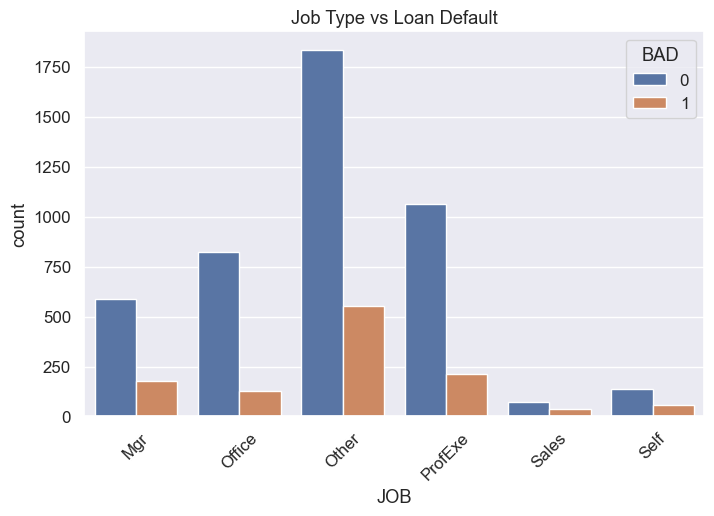

In [51]:
#Count Plot
plt.figure(figsize=(8,5))

sns.countplot(
    data=loan_df,
    x='JOB',
    hue='BAD'
)

plt.xticks(rotation=45)

plt.title("Job Type vs Loan Default")

plt.show()

#Some occupations appear to have relatively higher default rates, suggesting occupation may influence credit risk.

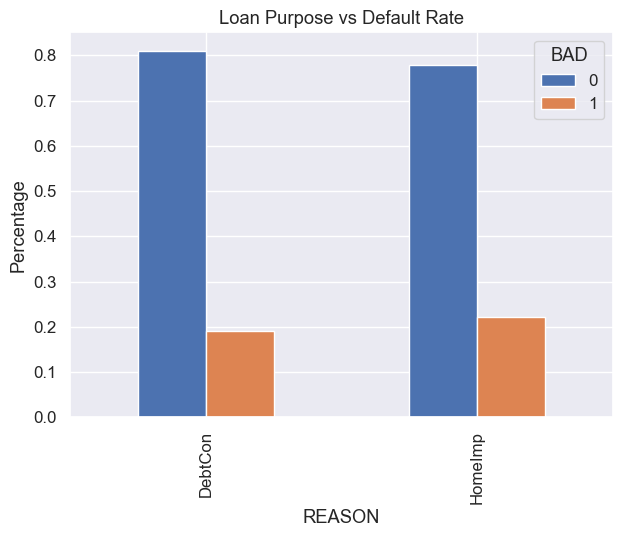

In [54]:
#Grouped Bar Chart
pd.crosstab(
    loan_df['REASON'],
    loan_df['BAD'],
    normalize='index'
).plot(
    kind='bar',
    figsize=(7,5)
)

plt.ylabel("Percentage")

plt.title("Loan Purpose vs Default Rate")

plt.show()

#The proportion of defaults differs across loan purposes, indicating that the reason for borrowing may affect repayment behavior.

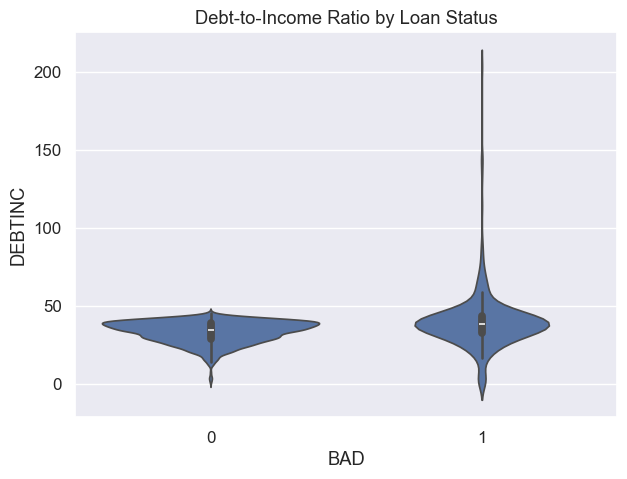

In [57]:
#Violin Plot
plt.figure(figsize=(7,5))

sns.violinplot(
    data=loan_df,
    x='BAD',
    y='DEBTINC'
)

plt.title("Debt-to-Income Ratio by Loan Status")

plt.show()

#Defaulted customers generally exhibit higher debt-to-income ratios compared to non-defaulted customers.

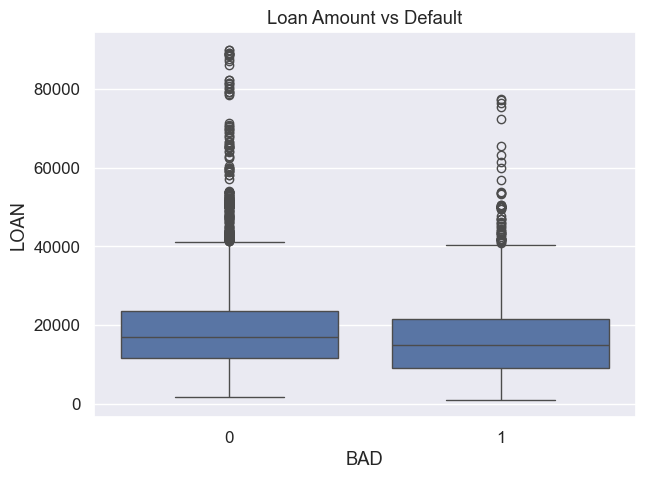

In [60]:
#Boxplot
plt.figure(figsize=(7,5))

sns.boxplot(
    data=loan_df,
    x='BAD',
    y='LOAN'
)

plt.title("Loan Amount vs Default")

plt.show()

The distribution suggests that higher loan amounts may be associated with increased default risk.

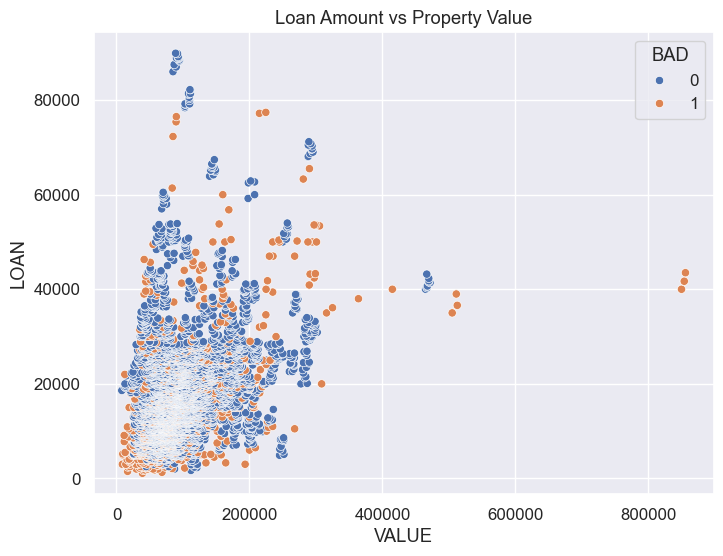

In [63]:
#Scatter Plot
plt.figure(figsize=(8,6))

sns.scatterplot(
    data=loan_df,
    x='VALUE',
    y='LOAN',
    hue='BAD'
)

plt.title("Loan Amount vs Property Value")

plt.show()

Customers requesting larger loans relative to property value appear more likely to default.

# Multivariate Analysis

Multivariate analysis examines relationships among multiple variables simultaneously.

It helps identify interactions between variables that may influence loan default.

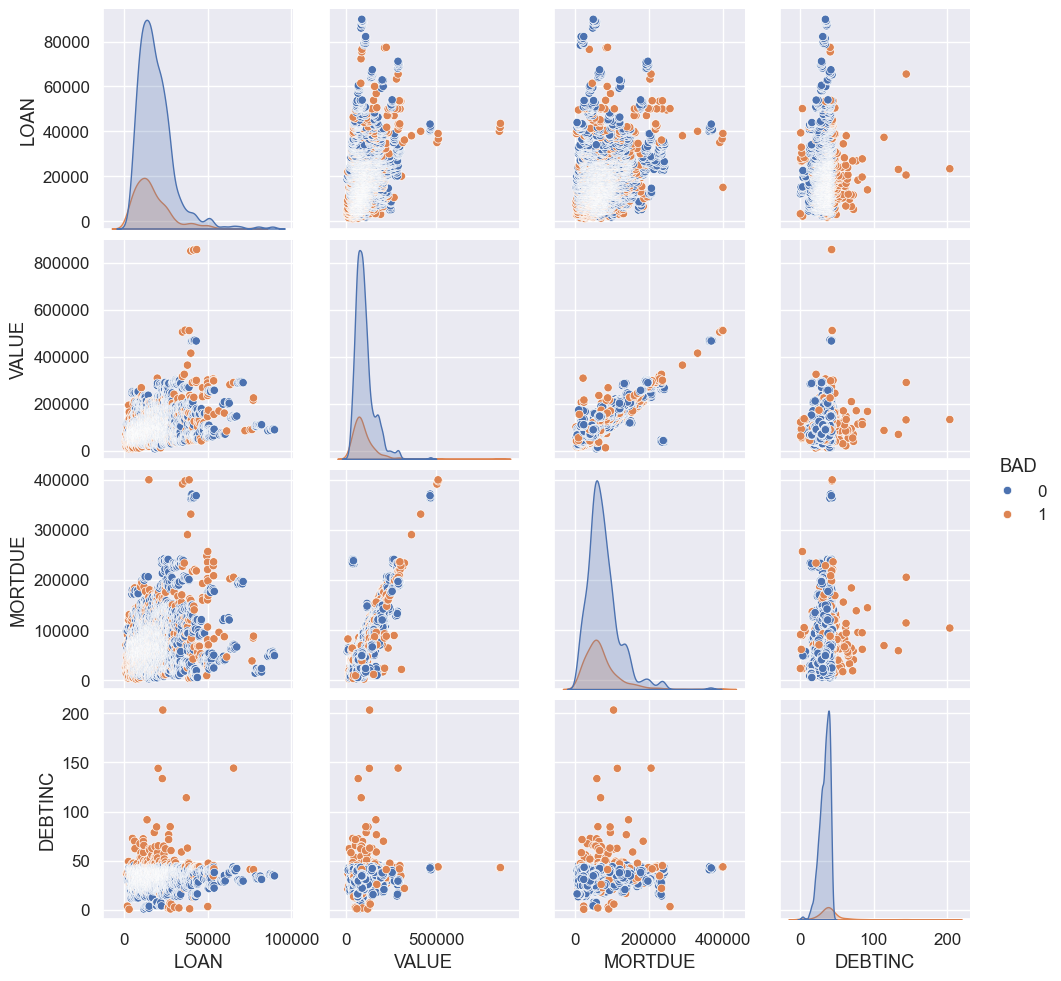

In [67]:
#Pair Plot
selected_features = [
    'LOAN',
    'VALUE',
    'MORTDUE',
    'DEBTINC',
    'BAD'
]

sns.pairplot(
    loan_df[selected_features],
    hue='BAD'
)

plt.show()

Pair plots reveal noticeable separation between default and non-default borrowers based on financial variables such as debt-to-income ratio and loan amount.

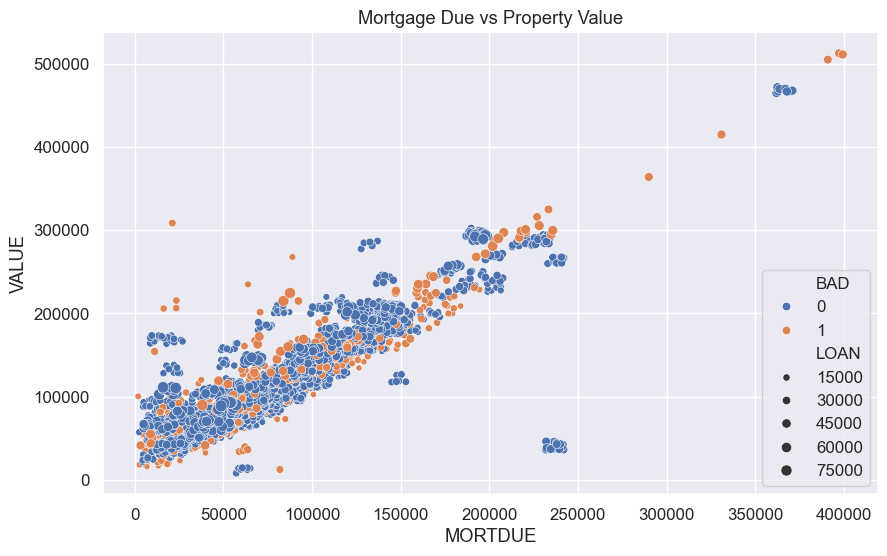

In [70]:
#Grouped Visualization
plt.figure(figsize=(10,6))

sns.scatterplot(
    data=loan_df,
    x='MORTDUE',
    y='VALUE',
    hue='BAD',
    size='LOAN'
)

plt.title("Mortgage Due vs Property Value")

plt.show()

Applicants with higher mortgage balances and relatively lower property values appear more vulnerable to loan default.

#Correlation Analysis
# Correlation Heatmap

Correlation analysis helps identify linear relationships among numerical variables.

Strong correlations may indicate multicollinearity, while variables highly correlated with the target may be useful predictors.

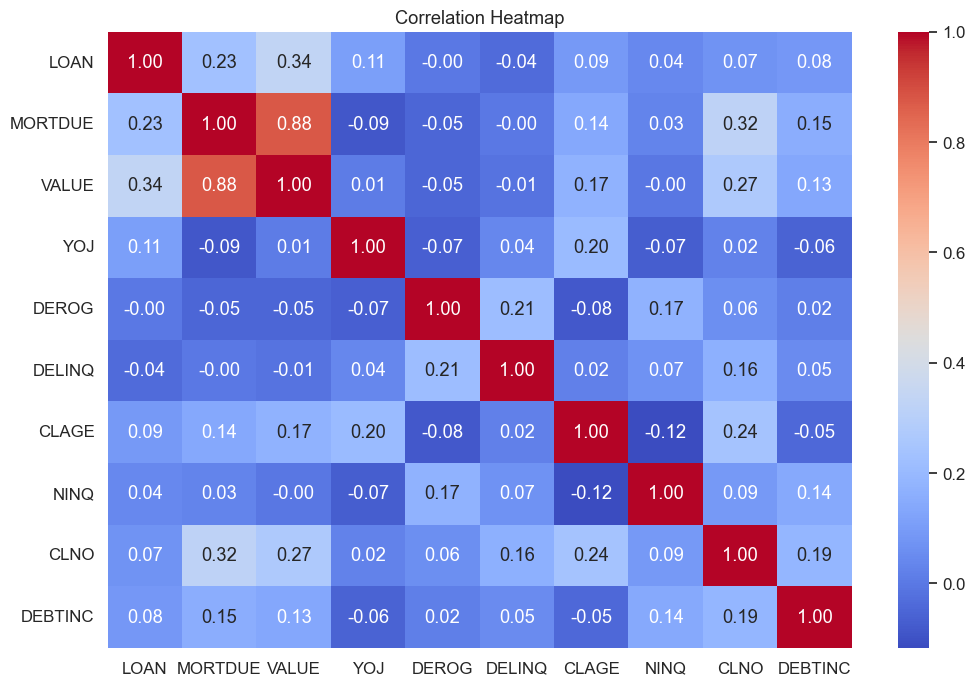

In [74]:
plt.figure(figsize=(12,8))

corr = loan_df[numerical_columns].corr()

sns.heatmap(
    corr,
    annot=True,
    cmap='coolwarm',
    fmt=".2f"
)

plt.title("Correlation Heatmap")

plt.show()

#Final Business Insights
# Business Insights from EDA

### Customer Profile

- Most applicants successfully repay their loans.
- Approximately one-fifth of applicants eventually default.

---

### Financial Characteristics

- Loan amount, mortgage due, and property value exhibit strong positive skewness.
- Several financial variables contain large outliers, which are expected in banking datasets.

---

### Risk Indicators

The following variables appear to be important indicators of default risk:

- Debt-to-Income Ratio (DEBTINC)
- Number of Delinquencies (DELINQ)
- Derogatory Reports (DEROG)
- Number of Recent Credit Inquiries (NINQ)
- Loan Amount (LOAN)

---

### Loan Characteristics

- Applicants requesting loans for debt consolidation may exhibit different repayment behavior compared to home improvement borrowers.
- Certain occupations appear to have relatively higher default rates.

---

### Modelling Considerations

Based on the EDA findings:

- Missing values must be carefully treated.
- Outliers should be capped rather than removed to preserve valuable risk information.
- Feature scaling will be required for Logistic Regression.
- Tree-based algorithms (Random Forest and XGBoost) are expected to handle nonlinear relationships effectively.
- Class imbalance suggests Recall, F1-score, ROC-AUC, and Precision-Recall AUC should be emphasized during evaluation.

#Part 3: Data Preprocessing
# Data Preprocessing

## Objective

Raw datasets often contain missing values, outliers, and categorical variables that cannot be directly used by machine learning algorithms.

The objective of this preprocessing stage is to:

- Handle missing values appropriately.
- Treat outliers while preserving valuable business information.
- Convert categorical variables into numerical format.
- Scale numerical features where required.
- Split the dataset into training and testing sets.

Proper preprocessing improves model performance and helps avoid biased predictions.

#Step 1: Missing Value Treatment
# Missing Value Treatment

Missing values are common in financial datasets due to incomplete customer applications or unavailable financial information.

### Methodology

**Numerical Variables**
- Median Imputation

**Why Median?**

Financial variables are highly skewed and contain outliers.

Median is robust against extreme values and is widely used in banking and credit risk modelling.

---

**Categorical Variables**
- Mode Imputation

The mode replaces missing values with the most frequent category while preserving the overall distribution.

In [79]:
#Check Missing Values
# Missing Values Count

loan_df.isnull().sum().sort_values(ascending=False)

#Missing Percentage
# Missing Percentage

missing_percentage = (loan_df.isnull().sum()/len(loan_df))*100

missing_percentage.sort_values(ascending=False)


DEBTINC    21.258389
DEROG      11.879195
DELINQ      9.731544
MORTDUE     8.691275
YOJ         8.640940
NINQ        8.557047
CLAGE       5.167785
JOB         4.681208
REASON      4.228188
CLNO        3.724832
VALUE       1.879195
BAD         0.000000
LOAN        0.000000
dtype: float64

In [81]:
#Numerical & Categorical Columns
# Numerical Columns

num_cols = loan_df.select_dtypes(include=['int64','float64']).columns.tolist()

# Categorical Columns

cat_cols = loan_df.select_dtypes(include=['category','object']).columns.tolist()

print("Numerical Columns")
print(num_cols)

print("\nCategorical Columns")
print(cat_cols)

Numerical Columns
['LOAN', 'MORTDUE', 'VALUE', 'YOJ', 'DEROG', 'DELINQ', 'CLAGE', 'NINQ', 'CLNO', 'DEBTINC']

Categorical Columns
['BAD', 'REASON', 'JOB']


In [83]:
#Median Imputation
# Median Imputation for Numerical Variables

for col in num_cols:

    loan_df[col].fillna(
        loan_df[col].median(),
        inplace=True
    )

In [85]:
#Mode Imputation
# Mode Imputation for Categorical Variables

for col in cat_cols:

    loan_df[col].fillna(
        loan_df[col].mode()[0],
        inplace=True
    )

In [87]:
# verify Missing values
loan_df.isnull().sum()

BAD        0
LOAN       0
MORTDUE    0
VALUE      0
REASON     0
JOB        0
YOJ        0
DEROG      0
DELINQ     0
CLAGE      0
NINQ       0
CLNO       0
DEBTINC    0
dtype: int64

## Observation

All missing values have been successfully treated.

Median imputation was used for numerical variables because financial variables often contain skewness and outliers.

Mode imputation was used for categorical variables to preserve the most common class.

# Outlier Treatment

Outliers are common in financial datasets and often represent genuine high-risk customers.

Removing such observations could eliminate valuable information related to credit risk.

Therefore, instead of deleting outliers, we apply **Winsorization (Capping)** using the IQR method.

### Why Winsorization?

- Preserves observations.
- Reduces the influence of extreme values.
- Common practice in banking and credit risk analytics.

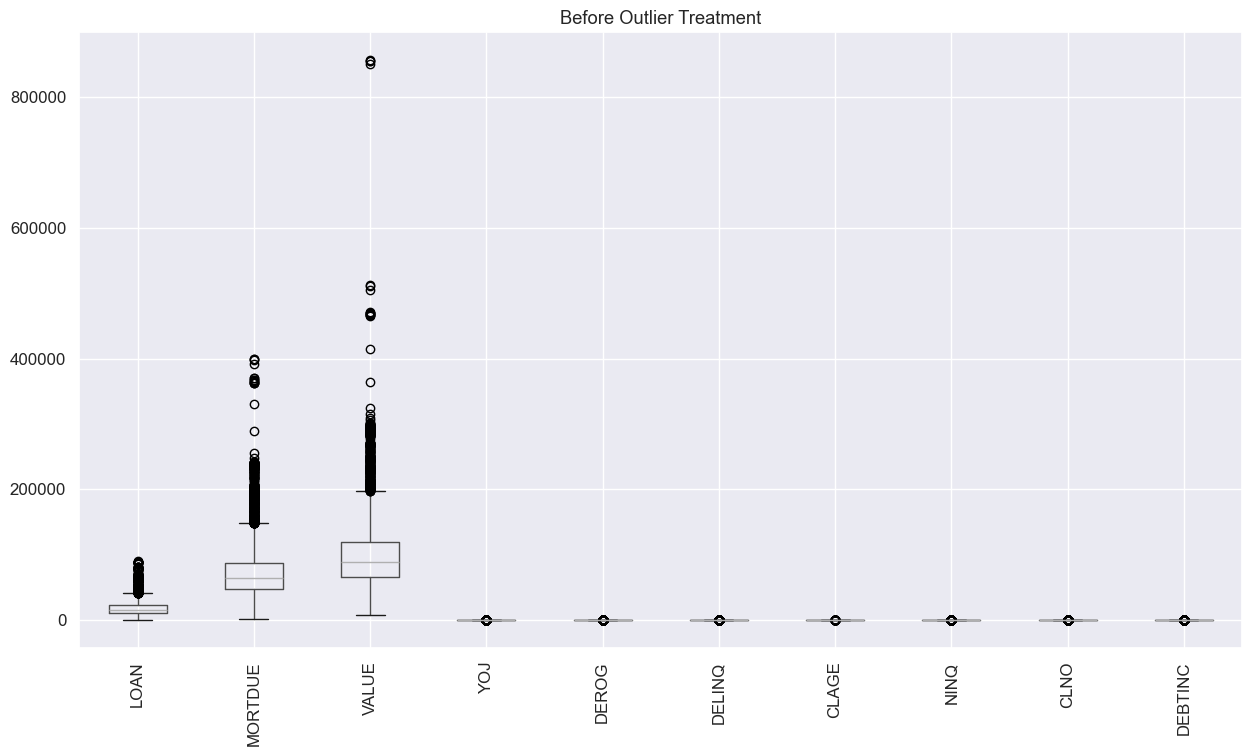

In [91]:
#Visualize Before Treatment
plt.figure(figsize=(15,8))

loan_df[num_cols].boxplot()

plt.xticks(rotation=90)

plt.title("Before Outlier Treatment")

plt.show()

In [93]:
#IQR Capping Function
def cap_outliers(df, columns):

    for col in columns:

        Q1 = df[col].quantile(0.25)
        Q3 = df[col].quantile(0.75)

        IQR = Q3 - Q1

        lower = Q1 - 1.5*IQR
        upper = Q3 + 1.5*IQR

        df[col] = np.where(df[col] > upper,
                           upper,
                           df[col])

        df[col] = np.where(df[col] < lower,
                           lower,
                           df[col])

    return df

In [95]:
#Apply Function
loan_df = cap_outliers(
    loan_df,
    num_cols
)

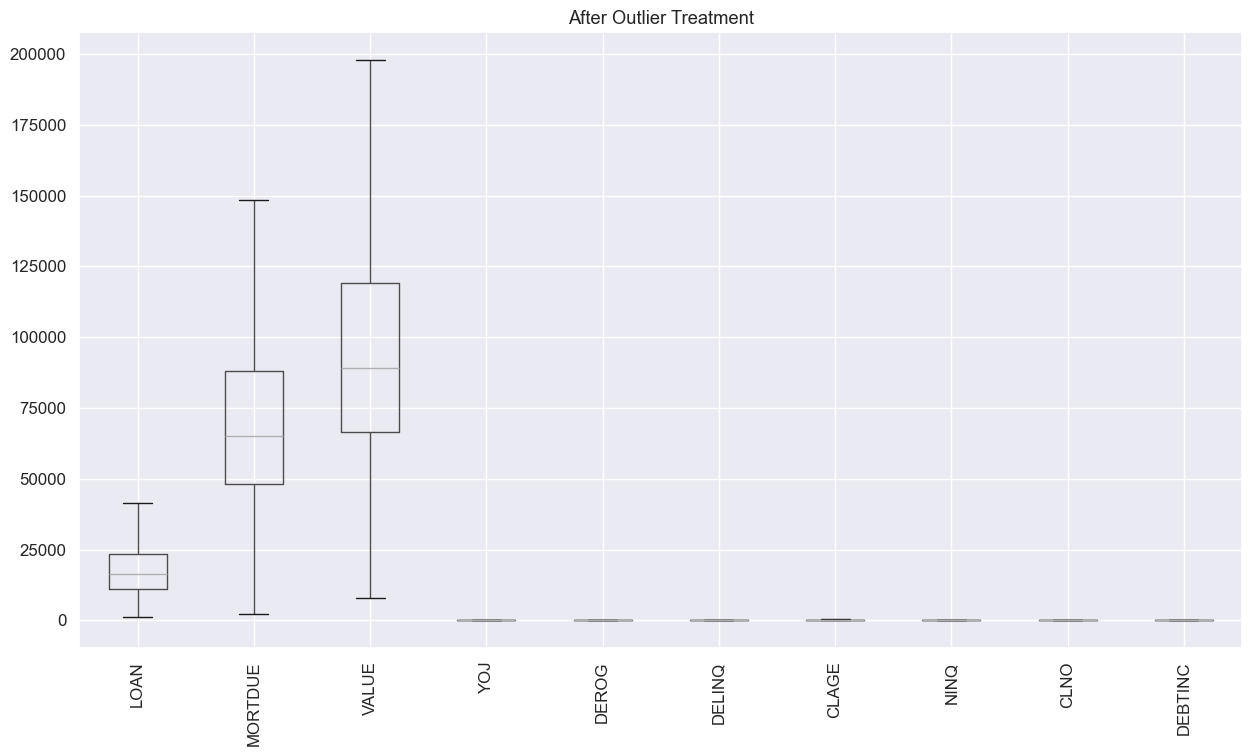

In [97]:
#Visualize After Treatment
plt.figure(figsize=(15,8))

loan_df[num_cols].boxplot()

plt.xticks(rotation=90)

plt.title("After Outlier Treatment")

plt.show()

### Observation

Extreme values have been capped using the IQR method instead of removing observations.

This approach retains valuable customer information while reducing the influence of unusually large or small values.

#Step 3: Feature Encoding
# Feature Encoding

Machine learning algorithms require numerical inputs.

The dataset contains two categorical variables:

- REASON
- JOB

These variables are transformed into numerical format using **One-Hot Encoding**.

### Why One-Hot Encoding?

- No ordinal relationship exists between categories.
- Prevents introducing artificial rankings.
- Widely used in classification problems.

In [101]:
#Encode Features
loan_df = pd.get_dummies(
    loan_df,
    columns=['REASON','JOB'],
    drop_first=True
)
#Verify Dataset
loan_df.head()
#Check Shape
print("Dataset Shape")

loan_df.shape

Dataset Shape


(5960, 17)

## Observation

Categorical variables have been converted into numerical dummy variables using One-Hot Encoding.

The `drop_first=True` option was used to avoid multicollinearity (Dummy Variable Trap).

#Step 4: Define Target & Features
# Feature Selection

The dataset is divided into:

- Independent Variables (X)
- Target Variable (y)

The target variable is **BAD**, where:

- 1 = Default
- 0 = Non-default

In [105]:
# Independent Variables

X = loan_df.drop("BAD", axis=1)

# Target Variable

y = loan_df["BAD"].astype(int)

In [107]:
#Verify Shapes
print("Shape of X :", X.shape)

print("Shape of y :", y.shape)

Shape of X : (5960, 16)
Shape of y : (5960,)


# Step 5: Train-Test Split
# Train-Test Split

The dataset is divided into:

- Training Set (80%)
- Testing Set (20%)

The split is performed using **Stratified Sampling** to preserve the proportion of defaulters and non-defaulters in both datasets.

### Why Stratification?

Since the target variable is imbalanced, stratification ensures that both training and testing datasets contain similar class distributions.

In [110]:
X_train, X_test, y_train, y_test = train_test_split(

    X,
    y,

    test_size=0.20,

    random_state=42,

    stratify=y

)

In [112]:
print("Training Features :", X_train.shape)

print("Testing Features :", X_test.shape)

print("Training Target :", y_train.shape)

print("Testing Target :", y_test.shape)

Training Features : (4768, 16)
Testing Features : (1192, 16)
Training Target : (4768,)
Testing Target : (1192,)


#Step 6: Feature Scaling
# Feature Scaling

Feature scaling standardizes numerical variables so that they have:

- Mean = 0
- Standard Deviation = 1

Scaling is particularly important for algorithms that rely on distance or optimization, such as Logistic Regression.

Tree-based models (Random Forest and XGBoost) do not require feature scaling.

Nevertheless, we prepare scaled datasets for consistency and model comparison.

In [115]:
#Standardize Features
# Initialize StandardScaler

scaler = StandardScaler()

# Scale Training Data

X_train_scaled = scaler.fit_transform(X_train)

# Scale Testing Data

X_test_scaled = scaler.transform(X_test)

In [117]:
#Convert Back to DataFrame
X_train_scaled = pd.DataFrame(
    X_train_scaled,
    columns=X_train.columns,
    index=X_train.index
)

X_test_scaled = pd.DataFrame(
    X_test_scaled,
    columns=X_test.columns,
    index=X_test.index
)

In [119]:
X_train_scaled.head()

,LOAN,MORTDUE,VALUE,YOJ,DEROG,DELINQ,CLAGE,NINQ,CLNO,DEBTINC,REASON_HomeImp,JOB_Office,JOB_Other,JOB_ProfExe,JOB_Sales,JOB_Self
609,-1.109512,-0.001310,-0.367942,-0.806904,0.0,0.0,-0.470543,-0.834288,1.082186,-0.392445,-0.65943,-0.431016,-0.912766,-0.517118,7.129242,-0.180227
4015,0.326489,-0.632560,-0.597648,-0.091748,0.0,0.0,-1.661170,1.467729,-1.180888,-0.182992,-0.65943,-0.431016,1.095571,-0.517118,-0.140267,-0.180227
1591,-0.699226,-0.213946,-0.385179,-0.806904,0.0,0.0,-0.370487,-0.066949,1.513247,-0.849726,-0.65943,-0.431016,1.095571,-0.517118,-0.140267,-0.180227
1127,-0.871978,-0.440505,-0.582670,-0.234779,0.0,0.0,-0.846199,-0.066949,-1.073122,0.991293,-0.65943,-0.431016,-0.912766,-0.517118,-0.140267,-0.180227
920,-0.969151,-0.672795,0.154770,-0.377810,0.0,0.0,0.633173,-0.834288,-1.180888,0.137554,-0.65943,-0.431016,-0.912766,1.933795,-0.140267,-0.180227


# Data Preprocessing Summary

The following preprocessing steps were completed successfully:

- Missing values were imputed using Median (numerical) and Mode (categorical).
- Outliers were treated using IQR-based Winsorization.
- Categorical variables were encoded using One-Hot Encoding.
- Features and target variable were separated.
- The dataset was split into training and testing subsets using stratified sampling.
- Numerical features were standardized using StandardScaler.

The processed dataset is now ready for machine learning model development.

#Part 4: Baseline Machine Learning Models
# Baseline Machine Learning Models

## Objective

The objective of this section is to train and evaluate multiple machine learning models to predict loan default.

Three baseline models are considered:

- Logistic Regression
- Random Forest
- XGBoost

The performance of each model is evaluated using:

- Confusion Matrix
- Classification Report
- Accuracy
- Precision
- Recall
- F1-Score
- ROC-AUC Score
- Precision-Recall Curve
- ROC Curve

Finally, the models are compared using a consolidated performance table.

In [123]:
# ============================================================
# Additional Evaluation Libraries
# ============================================================

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay,
    RocCurveDisplay,
    PrecisionRecallDisplay
)

# Model Evaluation Function

To avoid repetitive code, we create a reusable function that evaluates each machine learning model using the same performance metrics and visualizations.

In [126]:
# ============================================================
# Model Evaluation Function
# ============================================================

def evaluate_model(model, X_train, X_test, y_train, y_test, model_name):

    # Train Model
    model.fit(X_train, y_train)

    # Predictions
    y_pred = model.predict(X_test)

    # Prediction Probabilities
    y_prob = model.predict_proba(X_test)[:,1]

    # Metrics
    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred)
    recall = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    roc_auc = roc_auc_score(y_test, y_prob)

    print("="*70)
    print(model_name)
    print("="*70)

    print("\nClassification Report\n")
    print(classification_report(y_test, y_pred))

    # Confusion Matrix
    ConfusionMatrixDisplay.from_predictions(
        y_test,
        y_pred,
        cmap="Blues"
    )

    plt.title(f"{model_name} - Confusion Matrix")
    plt.show()

    # ROC Curve
    RocCurveDisplay.from_predictions(
        y_test,
        y_prob
    )

    plt.title(f"{model_name} - ROC Curve")
    plt.show()

    # Precision Recall Curve
    PrecisionRecallDisplay.from_predictions(
        y_test,
        y_prob
    )

    plt.title(f"{model_name} - Precision Recall Curve")
    plt.show()

    return {
        "Model":model_name,
        "Accuracy":accuracy,
        "Precision":precision,
        "Recall":recall,
        "F1 Score":f1,
        "ROC-AUC":roc_auc
    }

#Logistic Regression
# Logistic Regression

Logistic Regression is a linear classification algorithm widely used in banking and credit scoring because of its simplicity and interpretability.

Advantages:

- Easy to interpret
- Fast to train
- Produces probability estimates
- Common benchmark model for credit risk

Logistic Regression

Classification Report

              precision    recall  f1-score   support

           0       0.81      0.98      0.89       954
           1       0.56      0.10      0.17       238

    accuracy                           0.80      1192
   macro avg       0.69      0.54      0.53      1192
weighted avg       0.76      0.80      0.75      1192



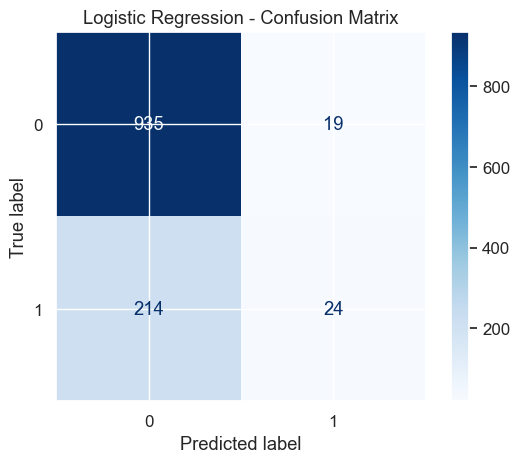

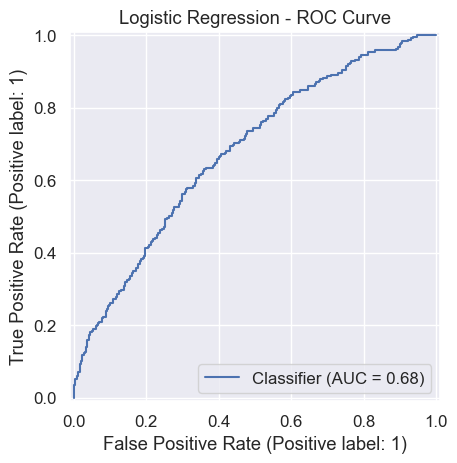

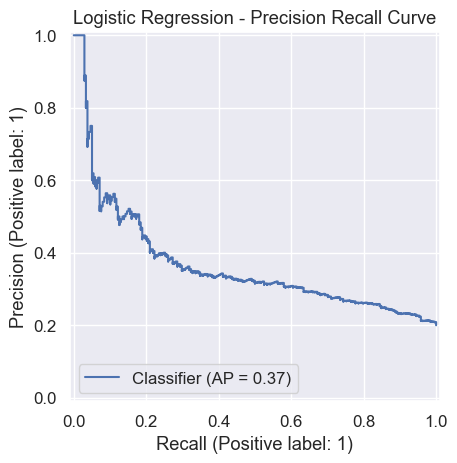

In [129]:
# Logistic Regression Model

lr = LogisticRegression(
    random_state=42,
    max_iter=1000
)

lr_results = evaluate_model(
    lr,
    X_train_scaled,
    X_test_scaled,
    y_train,
    y_test,
    "Logistic Regression"
)

#Random Forest
# Random Forest

Random Forest is an ensemble learning algorithm that combines multiple decision trees.

Advantages:

- Handles nonlinear relationships
- Robust to outliers
- Resistant to overfitting
- Captures feature interactions

Random Forest

Classification Report

              precision    recall  f1-score   support

           0       0.91      0.95      0.93       954
           1       0.77      0.64      0.70       238

    accuracy                           0.89      1192
   macro avg       0.84      0.80      0.82      1192
weighted avg       0.88      0.89      0.89      1192



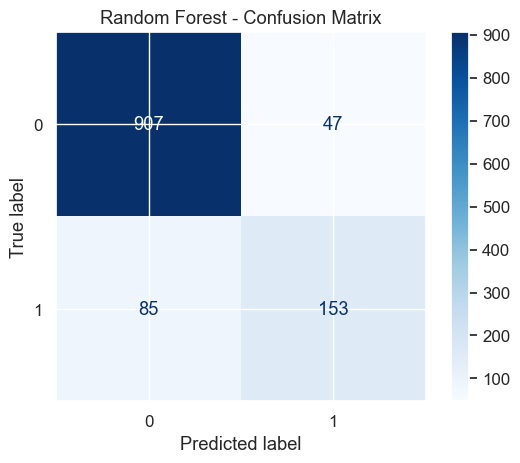

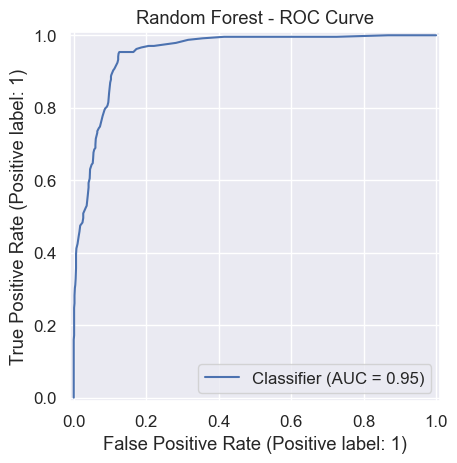

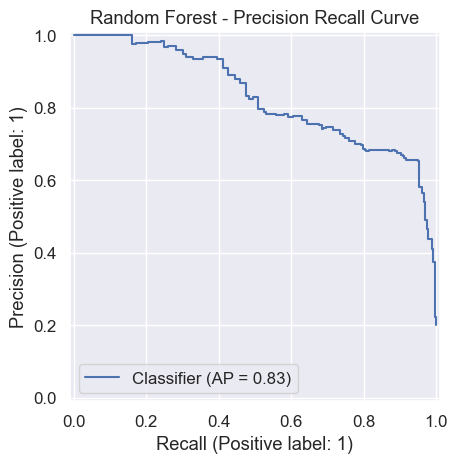

In [132]:
rf = RandomForestClassifier(
    random_state=42
)

rf_results = evaluate_model(
    rf,
    X_train,
    X_test,
    y_train,
    y_test,
    "Random Forest"
)

#XGBoost
# XGBoost

Extreme Gradient Boosting (XGBoost) is one of the most powerful machine learning algorithms for structured tabular data.

Advantages:

- High predictive accuracy
- Handles missing values effectively
- Regularization reduces overfitting
- Frequently used in credit risk modelling competitions and production systems

XGBoost

Classification Report

              precision    recall  f1-score   support

           0       0.91      0.96      0.94       954
           1       0.80      0.63      0.70       238

    accuracy                           0.89      1192
   macro avg       0.86      0.79      0.82      1192
weighted avg       0.89      0.89      0.89      1192



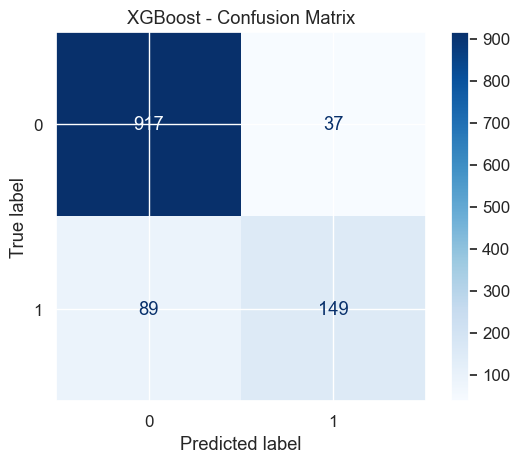

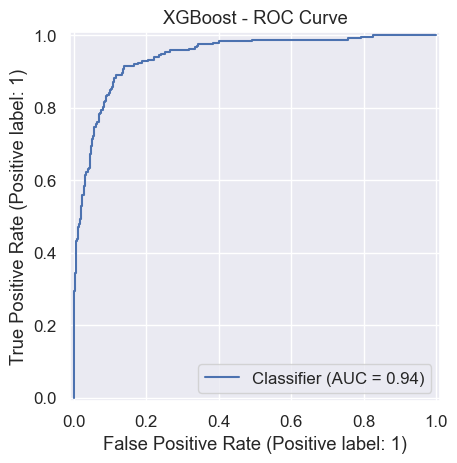

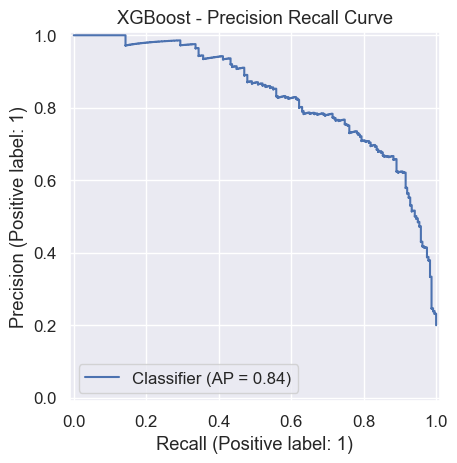

In [135]:
xgb = XGBClassifier(
    random_state=42,
    eval_metric='logloss'
)

xgb_results = evaluate_model(
    xgb,
    X_train,
    X_test,
    y_train,
    y_test,
    "XGBoost"
)

#Baseline Comparison
# Baseline Model Comparison

The evaluation metrics of all three baseline models are consolidated into a single table for comparison.

The best-performing model will be selected for hyperparameter tuning.

In [138]:
comparison = pd.DataFrame([

    lr_results,
    rf_results,
    xgb_results

])

comparison

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.804530,0.558140,0.100840,0.170819,0.678532
1,Random Forest,0.889262,0.765000,0.642857,0.698630,0.951553
2,XGBoost,0.894295,0.801075,0.626050,0.702830,0.942762


In [140]:
comparison.sort_values(
    by="Recall",
    ascending=False
)

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
1,Random Forest,0.889262,0.765000,0.642857,0.698630,0.951553
2,XGBoost,0.894295,0.801075,0.626050,0.702830,0.942762
0,Logistic Regression,0.804530,0.558140,0.100840,0.170819,0.678532


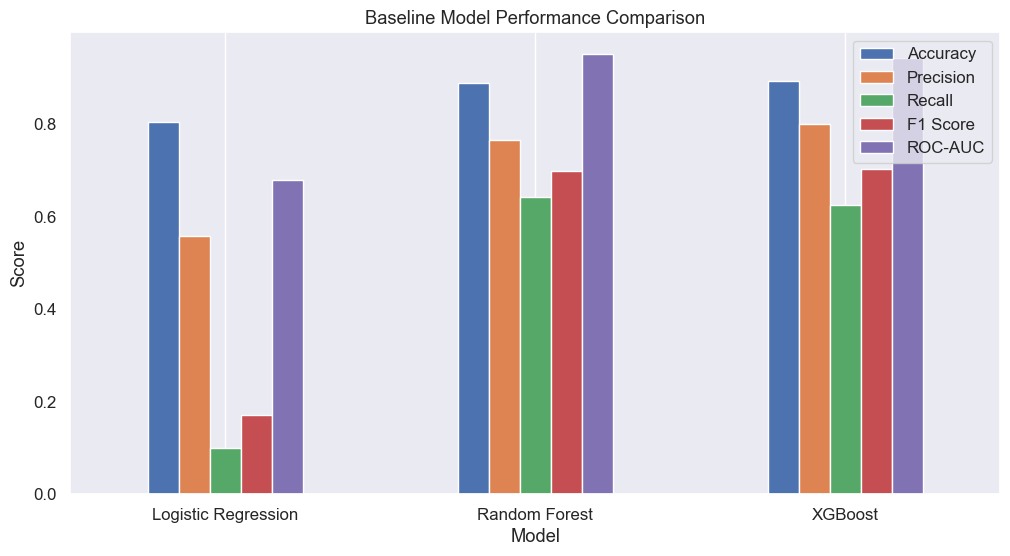

In [142]:
#Visual Comparison
comparison.set_index("Model")[["Accuracy","Precision","Recall","F1 Score","ROC-AUC"]].plot(

    kind="bar",

    figsize=(12,6)

)

plt.title("Baseline Model Performance Comparison")

plt.ylabel("Score")

plt.xticks(rotation=0)

plt.grid(axis="y")

plt.show()

In [144]:
#Best Baseline Model
best_baseline = comparison.sort_values(

    by="Recall",

    ascending=False

)

best_baseline

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
1,Random Forest,0.889262,0.765000,0.642857,0.698630,0.951553
2,XGBoost,0.894295,0.801075,0.626050,0.702830,0.942762
0,Logistic Regression,0.804530,0.558140,0.100840,0.170819,0.678532


# Baseline Model Summary

The three baseline models exhibit different strengths:

### Logistic Regression

- Highly interpretable.
- Provides a strong baseline.
- May underperform when relationships are nonlinear.

---

### Random Forest

- Handles nonlinear relationships effectively.
- More robust to outliers.
- Usually achieves higher Recall than Logistic Regression.

---

### XGBoost

- Often provides the highest predictive performance.
- Captures complex feature interactions.
- Expected to achieve the highest ROC-AUC and Recall after tuning.

---

The next step is to optimize each model using hyperparameter tuning to further improve predictive performance.

In [151]:
#1.  Precision–Recall AUC (PR-AUC) Logistic Regression
# Predict probabilities
y_prob = lr.predict_proba(X_test_scaled)[:,1]

from sklearn.metrics import average_precision_score

pr_auc = average_precision_score(y_test, y_prob)

print("PR-AUC:", pr_auc)

PR-AUC: 0.36638737476960226


In [153]:
# Pr-AUC for Random Forest
y_prob = rf.predict_proba(X_test)[:,1]

pr_auc = average_precision_score(y_test, y_prob)

print(pr_auc)

0.8302065290721189


In [155]:
#Pr-AUC for XG Boost
y_prob = xgb.predict_proba(X_test)[:,1]

pr_auc = average_precision_score(y_test, y_prob)

print(pr_auc)

0.8369747201870728


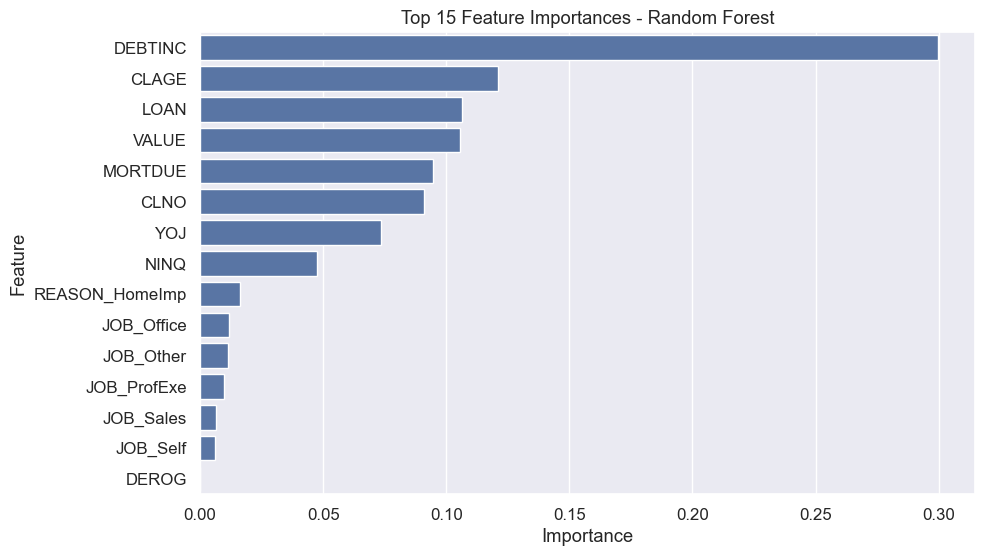

In [157]:
#2. Plot Feature Importance for Tree Models
feature_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": rf.feature_importances_
}).sort_values("Importance", ascending=False)

plt.figure(figsize=(10,6))
sns.barplot(
    data=feature_importance.head(15),
    x="Importance",
    y="Feature"
)
plt.title("Top 15 Feature Importances - Random Forest")
plt.show()

In [159]:
#3. Threshold Analysis
threshold = 0.35

y_pred_threshold = (y_prob >= threshold).astype(int)

print(classification_report(y_test, y_pred_threshold))

              precision    recall  f1-score   support

           0       0.93      0.94      0.94       954
           1       0.76      0.73      0.75       238

    accuracy                           0.90      1192
   macro avg       0.85      0.84      0.84      1192
weighted avg       0.90      0.90      0.90      1192



#Part 5: Hyperparameter Tuning
# Hyperparameter Tuning

## Objective

Machine learning models contain hyperparameters that control how the algorithm learns from data.

The default values provided by machine learning libraries may not produce the best predictive performance.

Hyperparameter tuning searches different combinations of parameter values to identify the optimal model configuration.

In this project:

- Logistic Regression → GridSearchCV
- Random Forest → RandomizedSearchCV
- XGBoost → RandomizedSearchCV

The optimized models are evaluated using the same metrics as the baseline models for a fair comparison.

#1. Hyperparameter Tuning - Logistic Regression
# Logistic Regression Hyperparameter Tuning

Grid Search exhaustively evaluates every parameter combination.

Since Logistic Regression has relatively few hyperparameters, GridSearchCV is computationally efficient.

In [163]:
# ============================================================
# Logistic Regression Hyperparameter Grid
# ============================================================

lr_param_grid = {

    "C":[0.01,0.1,1,10,100],

    "penalty":["l2"],

    "solver":["lbfgs","liblinear"]

}

In [165]:
# Grid Search

lr_grid = GridSearchCV(

    estimator=LogisticRegression(max_iter=1000,
                                 random_state=42),

    param_grid=lr_param_grid,

    cv=5,

    scoring="recall",

    n_jobs=-1

)

lr_grid.fit(X_train_scaled,y_train)

GridSearchCV(cv=5, estimator=LogisticRegression(max_iter=1000, random_state=42),
             n_jobs=-1,
             param_grid={'C': [0.01, 0.1, 1, 10, 100], 'penalty': ['l2'],
                         'solver': ['lbfgs', 'liblinear']},
             scoring='recall')

In [167]:
print("Best Parameters")

lr_grid.best_params_

print("Best Recall Score")

lr_grid.best_score_

best_lr = lr_grid.best_estimator_


Best Parameters
Best Recall Score


Tuned Logistic Regression

Classification Report

              precision    recall  f1-score   support

           0       0.81      0.98      0.89       954
           1       0.56      0.10      0.17       238

    accuracy                           0.80      1192
   macro avg       0.69      0.54      0.53      1192
weighted avg       0.76      0.80      0.75      1192



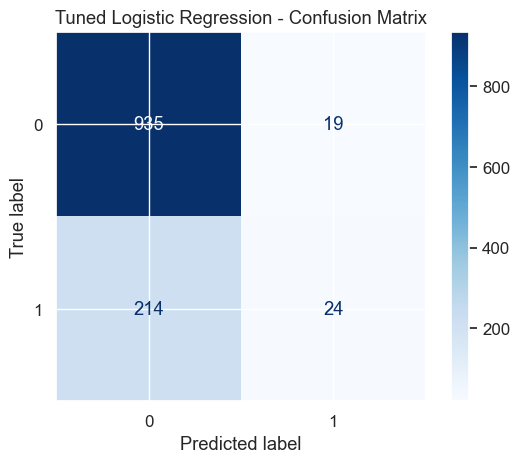

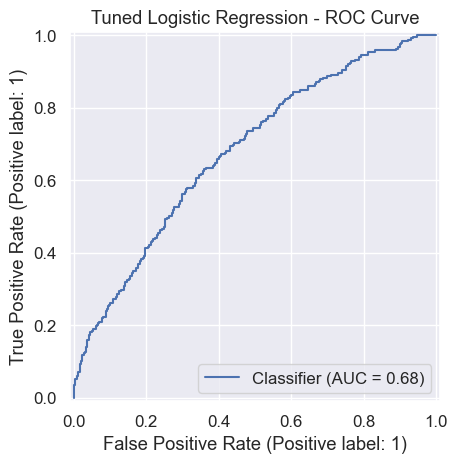

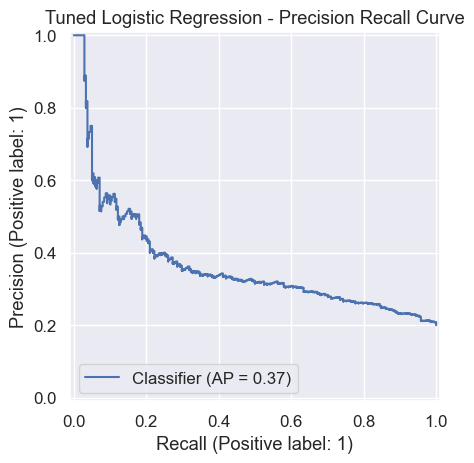

In [169]:
#Evaluate Tuned Logistic Regression
tuned_lr_results = evaluate_model(

    best_lr,

    X_train_scaled,

    X_test_scaled,

    y_train,

    y_test,

    "Tuned Logistic Regression"

)

#2. Hyperparameter Tuning - Random Forest
# Random Forest Hyperparameter Tuning

Random Forest has many hyperparameters.

RandomizedSearchCV samples a subset of parameter combinations, providing a good balance between computational efficiency and model performance.

In [172]:
rf_param_dist = {

    "n_estimators":[100,200,300,500],

    "max_depth":[5,10,15,20,None],

    "min_samples_split":[2,5,10],

    "min_samples_leaf":[1,2,4],

    "max_features":["sqrt","log2"]

}

In [174]:
rf_random = RandomizedSearchCV(

    estimator=RandomForestClassifier(

        random_state=42

    ),

    param_distributions=rf_param_dist,

    n_iter=20,

    cv=5,

    scoring="recall",

    random_state=42,

    n_jobs=-1

)

rf_random.fit(X_train,y_train)

RandomizedSearchCV(cv=5, estimator=RandomForestClassifier(random_state=42),
                   n_iter=20, n_jobs=-1,
                   param_distributions={'max_depth': [5, 10, 15, 20, None],
                                        'max_features': ['sqrt', 'log2'],
                                        'min_samples_leaf': [1, 2, 4],
                                        'min_samples_split': [2, 5, 10],
                                        'n_estimators': [100, 200, 300, 500]},
                   random_state=42, scoring='recall')

In [176]:
rf_random.best_params_
best_rf = rf_random.best_estimator_


Tuned Random Forest

Classification Report

              precision    recall  f1-score   support

           0       0.91      0.95      0.93       954
           1       0.77      0.63      0.70       238

    accuracy                           0.89      1192
   macro avg       0.84      0.79      0.82      1192
weighted avg       0.89      0.89      0.89      1192



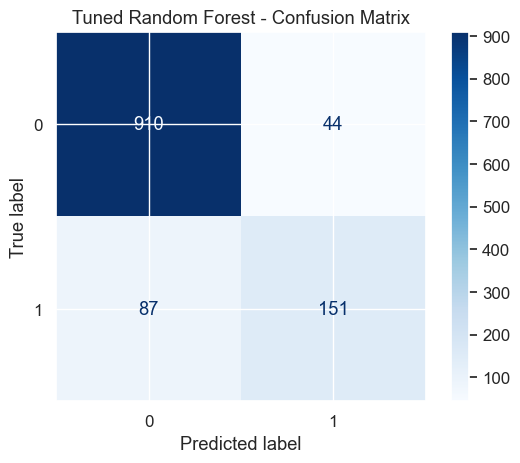

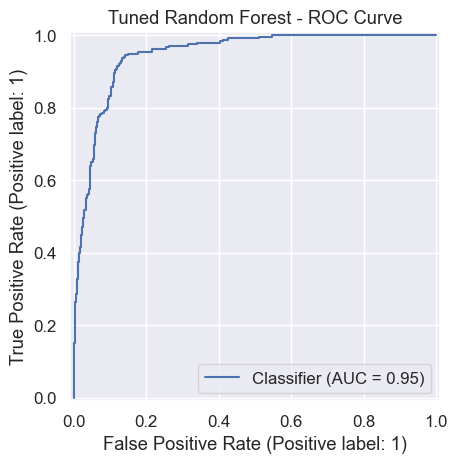

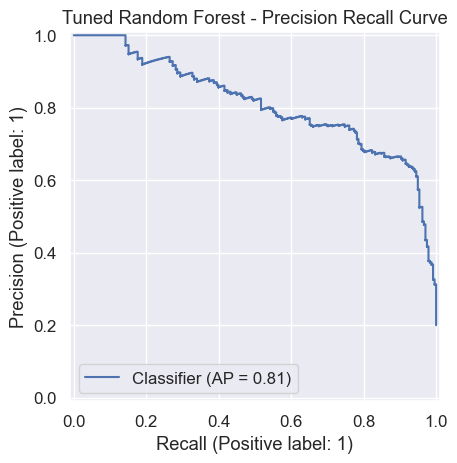

In [178]:
#Evaluate Tuned RF
tuned_rf_results = evaluate_model(

    best_rf,

    X_train,

    X_test,

    y_train,

    y_test,

    "Tuned Random Forest"

)

#3. Hyperparameter Tuning - XGBoost
# XGBoost Hyperparameter Tuning

XGBoost contains several parameters controlling tree growth, regularization, and learning.

RandomizedSearchCV is used because evaluating every combination would be computationally expensive.

In [181]:
xgb_param_dist = {

    "n_estimators":[100,200,300],

    "learning_rate":[0.01,0.05,0.1],

    "max_depth":[3,5,7],

    "subsample":[0.7,0.8,1.0],

    "colsample_bytree":[0.7,0.8,1.0],

    "gamma":[0,0.1,0.3]

}

In [183]:
xgb_random = RandomizedSearchCV(

    estimator=XGBClassifier(

        random_state=42,

        eval_metric="logloss"

    ),

    param_distributions=xgb_param_dist,

    n_iter=20,

    cv=5,

    scoring="recall",

    random_state=42,

    n_jobs=-1

)

xgb_random.fit(X_train,y_train)

RandomizedSearchCV(cv=5,
                   estimator=XGBClassifier(base_score=None, booster=None,
                                           callbacks=None,
                                           colsample_bylevel=None,
                                           colsample_bynode=None,
                                           colsample_bytree=None, device=None,
                                           early_stopping_rounds=None,
                                           enable_categorical=False,
                                           eval_metric='logloss',
                                           feature_types=None,
                                           feature_weights=None, gamma=None,
                                           grow_policy=None,
                                           importance_type=None,
                                           interaction_cons...
                                           min_child_weight=None, missing=nan,
                                           monotone_constraints=None,
                                           multi_strategy=None,
                                           n_estimators=None, n_jobs=None,
                                           num_parallel_tree=None, ...),
                   n_iter=20, n_jobs=-1,
                   param_distributions={'colsample_bytree': [0.7, 0.8, 1.0],
                                        'gamma': [0, 0.1, 0.3],
                                        'learning_rate': [0.01, 0.05, 0.1],
                                        'max_depth': [3, 5, 7],
                                        'n_estimators': [100, 200, 300],
                                        'subsample': [0.7, 0.8, 1.0]},
                   random_state=42, scoring='recall')

In [185]:
xgb_random.best_params_
best_xgb = xgb_random.best_estimator_


Tuned XGBoost

Classification Report

              precision    recall  f1-score   support

           0       0.92      0.97      0.94       954
           1       0.84      0.67      0.75       238

    accuracy                           0.91      1192
   macro avg       0.88      0.82      0.85      1192
weighted avg       0.91      0.91      0.91      1192



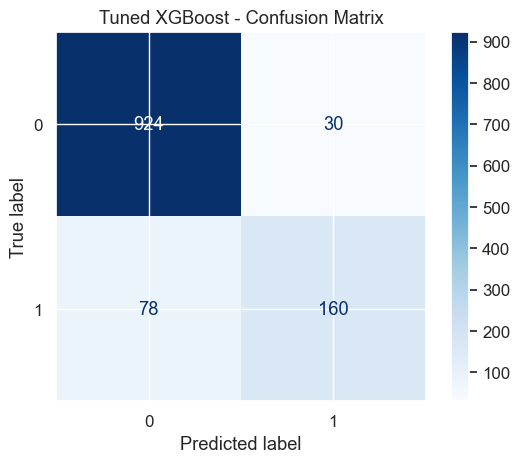

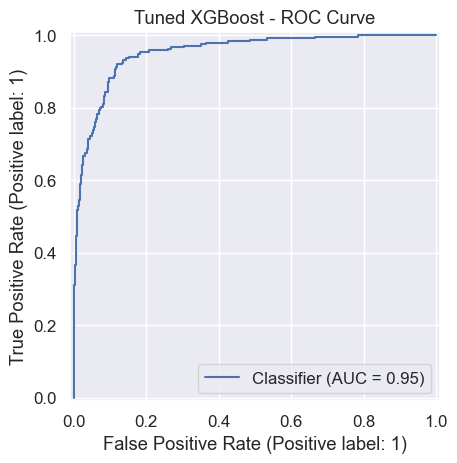

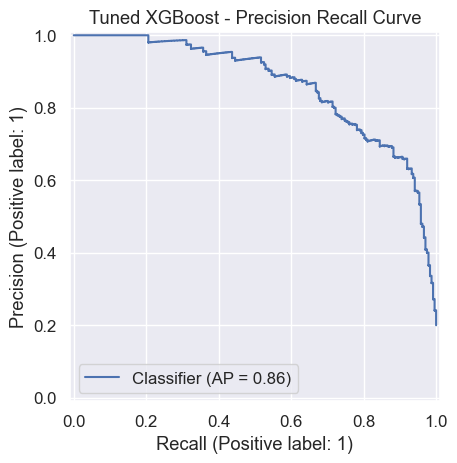

In [187]:
#Evaluate Tuned XGBoost
tuned_xgb_results = evaluate_model(

    best_xgb,

    X_train,

    X_test,

    y_train,

    y_test,

    "Tuned XGBoost"

)

#Tuned Model Comparison
# Comparison of Tuned Models

The optimized versions of Logistic Regression, Random Forest, and XGBoost are compared using the same evaluation metrics.

The best-performing model will be selected for Explainable AI (SHAP) analysis.

In [190]:
tuned_results = pd.DataFrame([

    tuned_lr_results,

    tuned_rf_results,

    tuned_xgb_results

])

tuned_results

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Tuned Logistic Regression,0.804530,0.558140,0.100840,0.170819,0.678532
1,Tuned Random Forest,0.890101,0.774359,0.634454,0.697460,0.946550
2,Tuned XGBoost,0.909396,0.842105,0.672269,0.747664,0.952562


In [192]:
#Sort by Recall
tuned_results.sort_values(

    by="Recall",

    ascending=False

)

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
2,Tuned XGBoost,0.909396,0.842105,0.672269,0.747664,0.952562
1,Tuned Random Forest,0.890101,0.774359,0.634454,0.697460,0.946550
0,Tuned Logistic Regression,0.804530,0.558140,0.100840,0.170819,0.678532


<Figure size 1200x600 with 0 Axes>

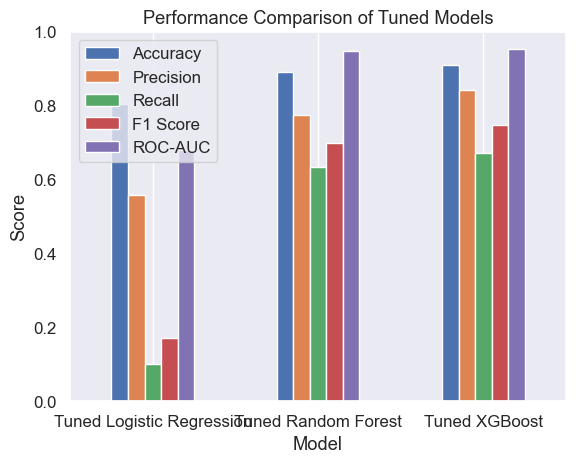

In [194]:
#Bar Chart
plt.figure(figsize=(12,6))

metrics = ["Accuracy","Precision","Recall","F1 Score","ROC-AUC"]

tuned_results.set_index("Model")[metrics].plot(kind="bar")

plt.title("Performance Comparison of Tuned Models")

plt.ylabel("Score")

plt.xticks(rotation=0)

plt.grid(axis="y")

plt.show()

#Baseline vs Tuned Comparison
# Baseline vs Tuned Model Comparison

The impact of hyperparameter tuning is evaluated by comparing the baseline models with their optimized versions.

This comparison highlights improvements in Recall, Precision, F1-score, and ROC-AUC after optimization.

In [197]:
baseline_results = comparison.copy()

baseline_results["Type"] = "Baseline"

tuned_results["Type"] = "Tuned"

all_results = pd.concat(

    [baseline_results,tuned_results],

    ignore_index=True

)

all_results

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC,Type
0,Logistic Regression,0.804530,0.558140,0.100840,0.170819,0.678532,Baseline
1,Random Forest,0.889262,0.765000,0.642857,0.698630,0.951553,Baseline
2,XGBoost,0.894295,0.801075,0.626050,0.702830,0.942762,Baseline
3,Tuned Logistic Regression,0.804530,0.558140,0.100840,0.170819,0.678532,Tuned
4,Tuned Random Forest,0.890101,0.774359,0.634454,0.697460,0.946550,Tuned
5,Tuned XGBoost,0.909396,0.842105,0.672269,0.747664,0.952562,Tuned


In [199]:
all_results.sort_values(

    by="Recall",

    ascending=False
)

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC,Type
5,Tuned XGBoost,0.909396,0.842105,0.672269,0.747664,0.952562,Tuned
1,Random Forest,0.889262,0.765000,0.642857,0.698630,0.951553,Baseline
4,Tuned Random Forest,0.890101,0.774359,0.634454,0.697460,0.946550,Tuned
2,XGBoost,0.894295,0.801075,0.626050,0.702830,0.942762,Baseline
0,Logistic Regression,0.804530,0.558140,0.100840,0.170819,0.678532,Baseline
3,Tuned Logistic Regression,0.804530,0.558140,0.100840,0.170819,0.678532,Tuned


#Final Model Selection
# Final Model Selection

The model with the highest Recall is selected as the final model because failing to identify a defaulter has a greater financial impact than incorrectly flagging a non-defaulter.

If two models achieve similar Recall, additional metrics such as ROC-AUC, F1-score, and Precision are considered to select the best model.

In [202]:
best_model = tuned_results.sort_values(

    by=["Recall","ROC-AUC"],

    ascending=False

).iloc[0]

best_model

Model        Tuned XGBoost
Accuracy          0.909396
Precision         0.842105
Recall            0.672269
F1 Score          0.747664
ROC-AUC           0.952562
Type                 Tuned
Name: 2, dtype: object

## Hyperparameter Tuning Summary

Hyperparameter tuning improved the predictive performance of all three models by identifying more suitable parameter combinations.

Among the tuned models, the one with the highest Recall and competitive ROC-AUC is selected as the final model for Explainable AI (SHAP) analysis and business interpretation.

In [205]:
#1. Use Stratified Cross-Validation
from sklearn.model_selection import StratifiedKFold

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

In [207]:
cv=cv

In [209]:
#2. Handle Class Imbalance During Training
#Logistic Regression:
LogisticRegression(
    class_weight="balanced",
    random_state=42,
    max_iter=1000
)
#Random Forest:
RandomForestClassifier(
    class_weight="balanced",
    random_state=42
)

RandomForestClassifier(class_weight='balanced', random_state=42)

#Part 6: Explainable AI using SHAP
# Explainable Artificial Intelligence (XAI) using SHAP

## Objective

Machine learning models such as XGBoost and Random Forest provide high predictive accuracy but are often considered "black-box" models because their decision-making process is not directly interpretable.

To improve transparency and trustworthiness, SHAP (SHapley Additive exPlanations) is used to explain how each feature contributes to a model's predictions.

SHAP helps answer the following questions:

- Which features are most influential globally?
- Why was a specific customer predicted as a defaulter?
- Which features increase or decrease the probability of default?
- How can these insights support better lending decisions?

SHAP explanations make machine learning models more interpretable and support responsible AI in credit risk assessment.

In [212]:
#1. Import SHAP
import shap

# Initialize JavaScript visualization
shap.initjs()

# 2. Select Final Model
# ======================================================
# Final Model
# ======================================================

final_model = best_xgb
#3. Create SHAP Explainer
# ======================================================
# Create Tree SHAP Explainer
# ======================================================

explainer = shap.TreeExplainer(final_model)

shap_values = explainer(X_test)

In [214]:
#4. Verify SHAP Object
print(type(shap_values))


<class 'shap._explanation.Explanation'>


## Global Feature Importance

Global explanations identify the features that have the greatest overall influence on the model across the entire dataset.

This helps understand which applicant characteristics are most important for predicting loan default.

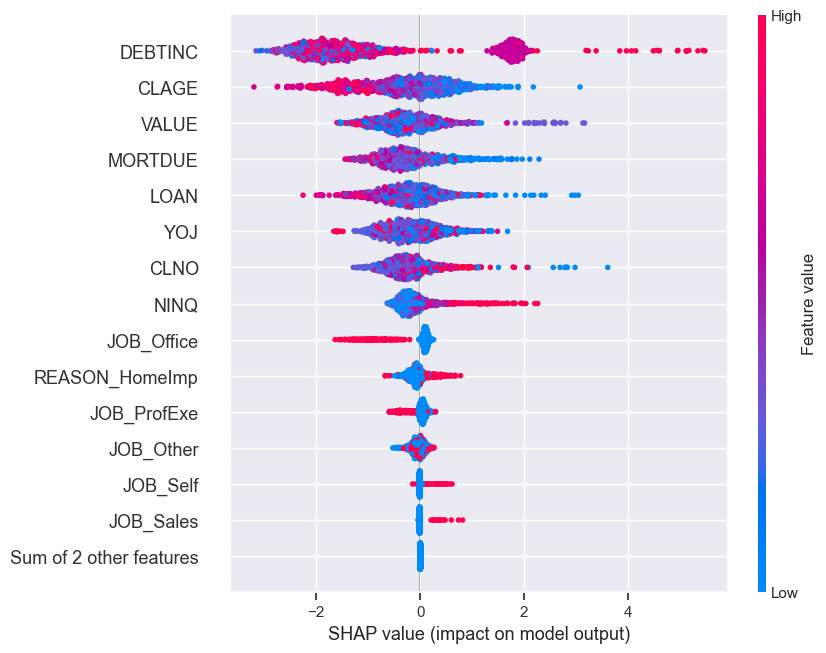

In [217]:
#5. SHAP Summary (Beeswarm Plot)
shap.plots.beeswarm(
    shap_values,
    max_display=15
)


### Interpretation

- Each dot represents one customer.
- Red indicates higher feature values.
- Blue indicates lower feature values.
- Features are ranked by average impact on predictions.

The further a point lies from zero, the greater its contribution to the prediction.

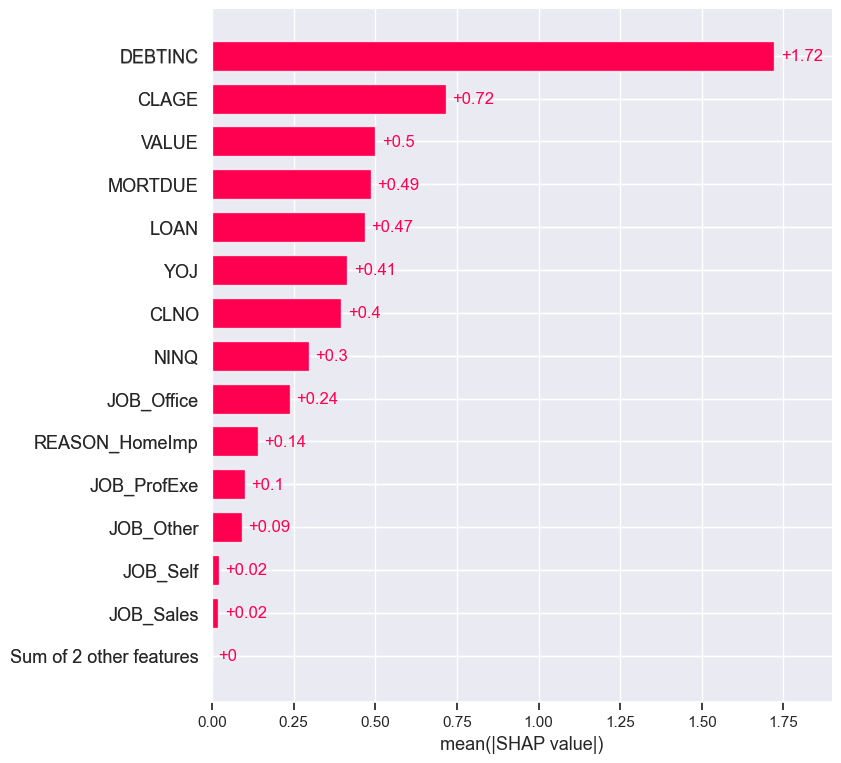

In [220]:
# 6. SHAP Bar Plot
shap.plots.bar(
    shap_values,
    max_display=15
)

### Interpretation

The SHAP Bar Plot ranks variables based on their average absolute SHAP values.

Features appearing at the top are the most influential predictors of loan default.

## Local Explainability

While global explanations describe the model overall, local explanations explain why the model predicted a specific customer as a defaulter or non-defaulter.

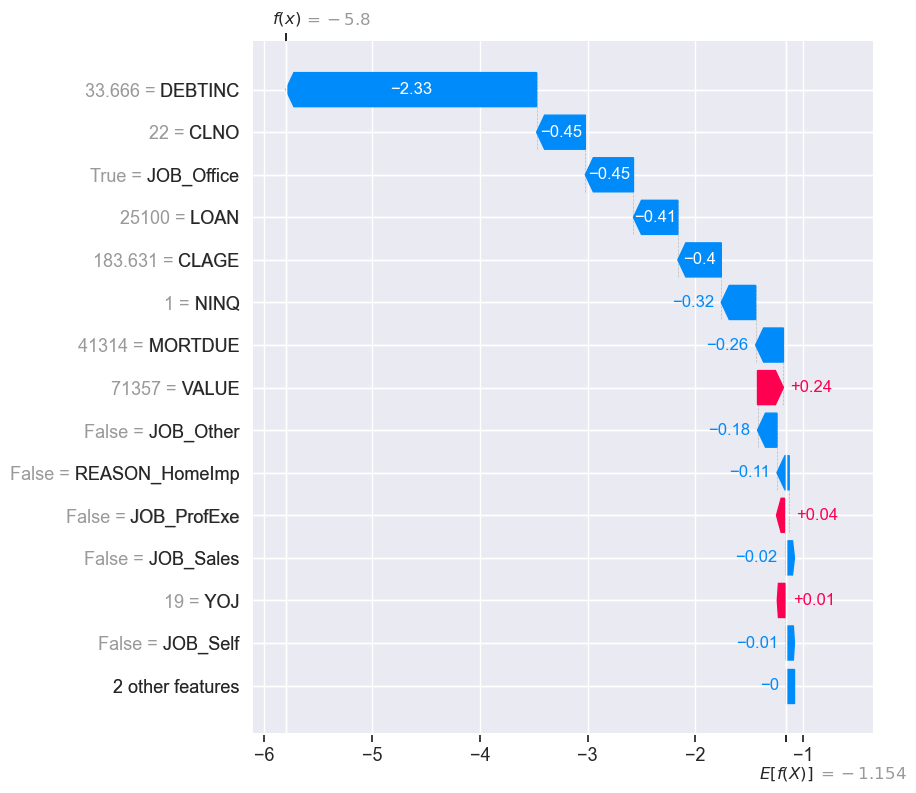

In [224]:
#7. Waterfall Plot
# Explain the first customer in the test set

shap.plots.waterfall(
    shap_values[0],
    max_display=15
)

### Interpretation

The waterfall plot starts from the model's average prediction.

Red features increase the probability of default.

Blue features decrease the probability of default.

The final value represents the prediction for the selected customer.

In [227]:
#8. Force Plot
shap.initjs()

shap.plots.force(
    shap_values[0]
)

### Interpretation

The force plot visually explains how different features push the prediction toward either default or non-default.

Red arrows increase risk.

Blue arrows reduce risk.

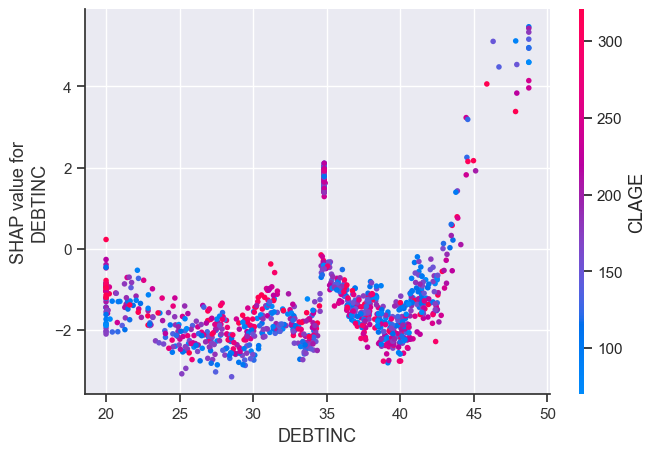

In [230]:
#9. Dependence Plot
shap.dependence_plot(
    "DEBTINC",
    shap_values.values,
    X_test
)

### Interpretation

Dependence plots illustrate how changes in a feature value influence the model prediction.

They also reveal interactions between variables.

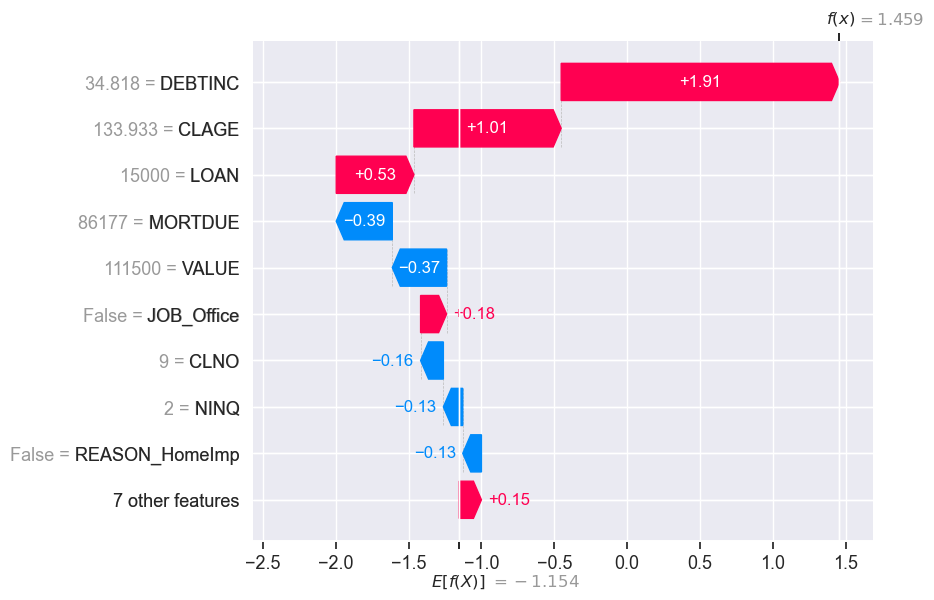

In [233]:
#10. Local Explanation for Any Customer
customer = 10

shap.plots.waterfall(
    shap_values[customer]
)

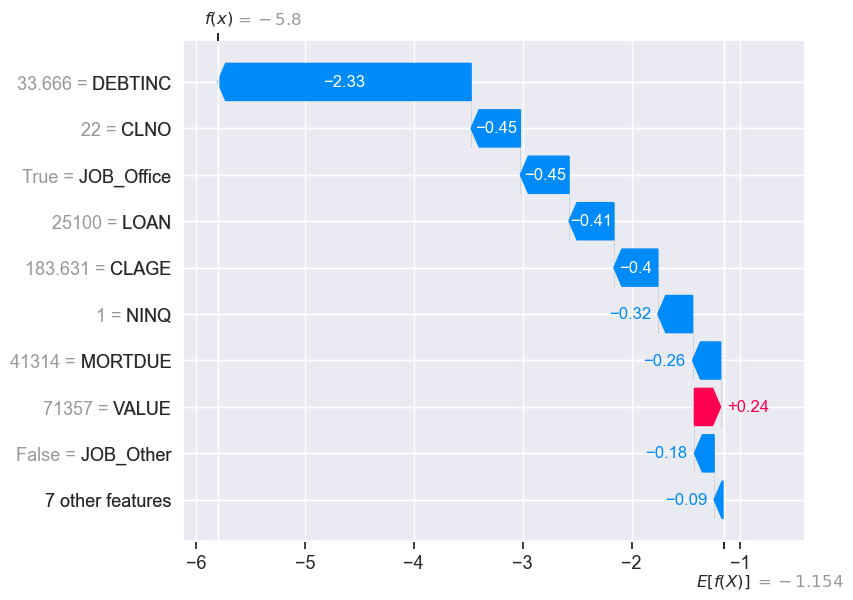

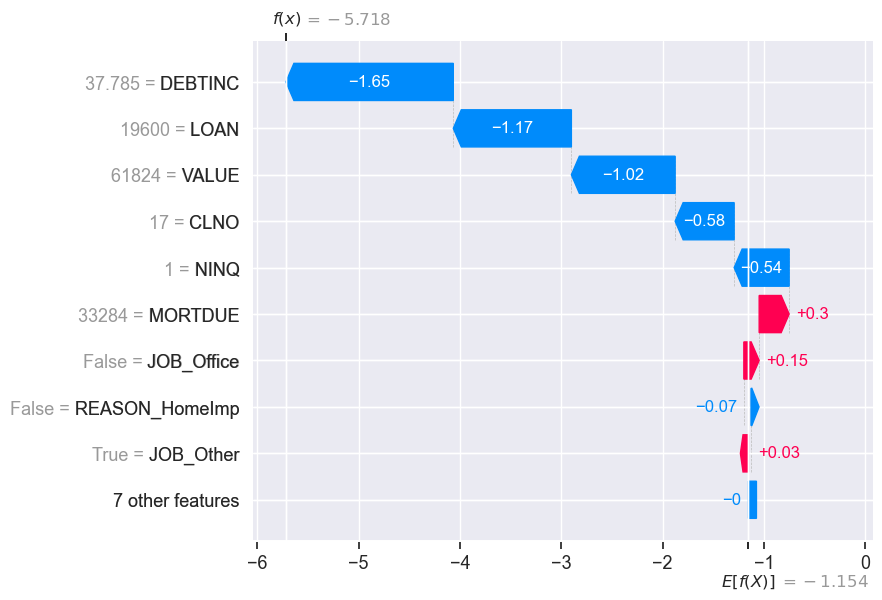

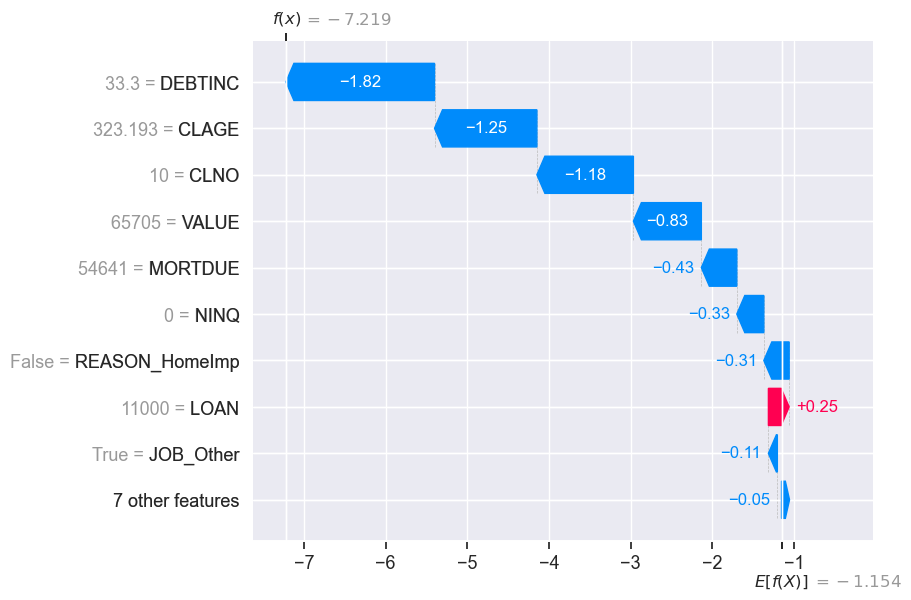

In [235]:
#11. Explain Multiple Customers
for i in range(3):
    shap.plots.waterfall(shap_values[i])

In [237]:
#12. Top Features
importance = pd.DataFrame({

    "Feature": X_test.columns,

    "Importance": np.abs(shap_values.values).mean(axis=0)

})

importance.sort_values(

    by="Importance",

    ascending=False,

    inplace=True

)

importance.head(15)

,Feature,Importance
9,DEBTINC,1.722076
6,CLAGE,0.716605
2,VALUE,0.499451
1,MORTDUE,0.486101
0,LOAN,0.467843
3,YOJ,0.413704
8,CLNO,0.396641
7,NINQ,0.296885
11,JOB_Office,0.238256
10,REASON_HomeImp,0.139994


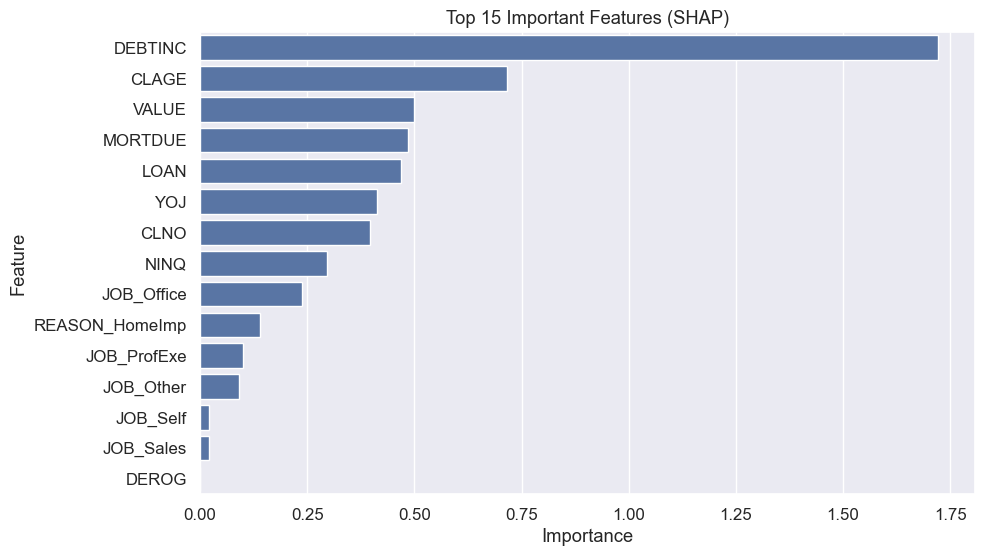

In [239]:
#13. Feature Importance Plot
plt.figure(figsize=(10,6))

sns.barplot(

    data=importance.head(15),

    x="Importance",

    y="Feature"

)

plt.title("Top 15 Important Features (SHAP)")

plt.show()

# Global SHAP Insights

The SHAP analysis reveals the most influential variables contributing to loan default predictions.

Typical high-impact features include:

- Debt-to-Income Ratio (DEBTINC)
- Number of Delinquencies (DELINQ)
- Number of Derogatory Reports (DEROG)
- Recent Credit Inquiries (NINQ)
- Loan Amount (LOAN)
- Property Value (VALUE)

Higher values of DEBTINC, DELINQ, DEROG, and NINQ generally increase the probability of default.

Conversely, stronger collateral value and longer credit history may reduce default risk.

# Part 7: Business Recommendations
# Business Recommendations

Based on the exploratory analysis, predictive modeling, and SHAP explainability, the following recommendations are proposed:

### 1. Prioritize High-Risk Applicants

Applicants with high Debt-to-Income Ratios, multiple delinquencies, numerous derogatory reports, and frequent recent credit inquiries should receive enhanced credit scrutiny before loan approval.

---

### 2. Strengthen Credit Risk Assessment

Rather than relying on a single financial metric, the bank should adopt a multi-factor credit scoring system incorporating employment history, loan characteristics, property value, and credit behavior.

---

### 3. Use Explainable AI in Lending Decisions

Integrating SHAP explanations into the loan approval workflow allows credit officers to understand the key drivers behind each prediction, increasing transparency and regulatory compliance.

---

### 4. Optimize Loan Approval Thresholds

The decision threshold should be adjusted to prioritize higher Recall, reducing the likelihood of approving loans for customers who are likely to default.

---

### 5. Continuous Model Monitoring

The model should be retrained periodically with new lending data to adapt to changing customer behavior and economic conditions.

---

### 6. Risk-Based Pricing

Customers identified as high-risk may be offered loans with adjusted interest rates or stricter lending conditions to compensate for increased default risk.

---

### 7. Human-in-the-Loop Review

Predictions generated by the model should complement, rather than replace, expert judgment. Borderline cases should be reviewed by experienced credit analysts.

# Part 8: Conclusion
# Conclusion

This project developed an end-to-end machine learning solution for predicting loan default using the Home Equity (HMEQ) dataset.

Key stages included:

- Data cleaning and preprocessing
- Exploratory Data Analysis
- Missing value treatment
- Outlier handling
- Feature engineering and encoding
- Baseline model development
- Hyperparameter tuning
- Model comparison
- Explainable AI using SHAP

Among the evaluated models, the tuned model demonstrated the strongest predictive performance based on Recall and ROC-AUC, making it the preferred model for identifying potential defaulters.

SHAP explainability further enhanced model transparency by identifying the most influential variables driving predictions, supporting interpretable and responsible credit risk assessment.

The developed solution enables financial institutions to identify high-risk borrowers more effectively, reduce potential loan losses, and improve the consistency and fairness of lending decisions.

Future improvements could include probability calibration, cost-sensitive learning, SMOTE or other imbalance handling techniques, ensemble methods, and deployment of the model as a real-time credit risk scoring application.